# Model predykcji wskaźnika Cena / Zysk (C/Z)

Moddel predykcji wskaznika Cena / Zysk (C/Z) na podstawie innych wskaznikow fundamentalnych spolek notowanych na gieldach swiatowych. Wskaznik C/Z jest jednym z najwazniejszych wskaznikow wyceny spolek i jest szeroko stosowany w analizie fundamentalnej. Model predykcji C/Z moze byc wykorzystany do oceny atrakcyjnosci inwestycyjnej spolek oraz do podejmowania decyzji inwestycyjnych.

---

**Źródło:** [mehdiaminazadeh/global-stock-market-dataset](https://www.kaggle.com/datasets/mehdiaminazadeh/global-stock-market-dataset)

## 1. Przygotowanie danych

W tej sekcji łączymy siedem plików CSV w jedną tabelę spółek, czyścimy liczby i liczymy wskaźniki pochodne.

### 1a. Pobranie danych

Kagglehub pobiera dataset `mehdiaminazadeh/global-stock-market-dataset` i zwraca ścieżkę do plików CSV.

In [198]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [199]:
# Download latest version
path = kagglehub.dataset_download("mehdiaminazadeh/global-stock-market-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\huber\.cache\kagglehub\datasets\mehdiaminazadeh\global-stock-market-dataset\versions\1


### 1b. Wczytanie i połączenie plików

Siedem plików łączymy po `ticker`, a bazą jest `tradingview_all_stocks`, bo ma target. Po połączeniu jest 36 kolumn.

Każdy z siedmiu plików wczytujemy osobno. Bazą jest `tradingview_all_stocks` (ma target). Do niej dołączamy pozostałe pliki po `ticker`, w lewo.

In [200]:
raw = {f[:-4]: pd.read_csv(os.path.join(path, f)) for f in os.listdir(path) if f.endswith(".csv")}
file_shapes = pd.DataFrame.from_dict(
    {name: {"wiersze": t.shape[0], "kolumny": t.shape[1]} for name, t in raw.items()}, orient="index"
)
print("Wczytane pliki i ich rozmiary:")
display(file_shapes)
STAGES = [("plik bazowy tradingview_all_stocks", *raw["tradingview_all_stocks"].shape)]

Wczytane pliki i ich rozmiary:


,wiersze,kolumny
balance_sheet,11821,12
cashflow,11821,4
dividends,11823,5
income_statement,11821,7
profitability,11823,7
tradingview_all_stocks,11806,10
tradingview_performance,11814,17


In [201]:
# łączymy wszystko po tickerze; kolumny już obecne w bazie pomijamy, name i close usuwamy (nie są cechami)
df = raw["tradingview_all_stocks"].drop(columns=["name", "close"])
for name, t in raw.items():
    if name == "tradingview_all_stocks":
        continue
    new_cols = [c for c in t.columns if c not in df.columns and c not in ("name", "close")]
    df = df.merge(t[["ticker"] + new_cols], on="ticker", how="left")
print("Wiersze po połączeniu:", len(df), "| unikalne tickery:", df["ticker"].nunique())
STAGES.append(("po połączeniu plików", *df.shape))
print("Kolumn po połączeniu:", df.shape[1])

Wiersze po połączeniu: 14249 | unikalne tickery: 11675
Kolumn po połączeniu: 36


**Powtórki tickerów:** sprawdzamy je raz, na połączonym zbiorze. Powtórka to kilka wierszy dla tej samej spółki. Zostawiamy pierwszy wiersz każdego tickera.

In [202]:
# jedno sprawdzenie na połączonym zbiorze
dup_mask = df["ticker"].duplicated(keep=False)
N_DUP_ROWS = int(dup_mask.sum())
conflicts = df[dup_mask].drop_duplicates().groupby("ticker").size()
print("Wiersze z powtórzonym tickerem:", N_DUP_ROWS, "| tickery:", df.loc[dup_mask, "ticker"].nunique())
print("Tickery z różnymi wartościami między wierszami:", int((conflicts > 1).sum()), list(conflicts[conflicts > 1].index))
df = df.drop_duplicates("ticker", keep="first")
print("Po usunięciu powtórek:", df.shape)
STAGES.append(("po usunięciu powtórek", *df.shape))

Wiersze z powtórzonym tickerem: 2890 | tickery: 316
Tickery z różnymi wartościami między wierszami: 1 ['NASDAQ:CLWT']
Po usunięciu powtórek: (11675, 36)


In [203]:
# podgląd połączonych danych przed czyszczeniem (wartości nadal jako tekst)
print("Wymiar przed czyszczeniem:", df.shape)
display(df.head())

Wymiar przed czyszczeniem: (11675, 36)


,ticker,change,change_abs,volume,market_cap_basic,price_earnings_ttm,sector,industry,total_assets_fq,cash_n_short_term_invest_fq,total_liabilities_fq,total_debt_fq,net_debt_fq,total_equity_fq,current_ratio_fq,quick_ratio_fq,debt_to_equity_fq,free_cash_flow_ttm,dividends_yield,dividend_payout_ratio_ttm,total_revenue_ttm,gross_profit_ttm,net_income_ttm,ebitda_ttm,gross_margin_ttm,operating_margin_ttm,net_margin_ttm,ebitda_margin_ttm,Perf.W,Perf.1M,Perf.3M,Perf.6M,Perf.YTD,Perf.Y,Perf.5Y,Perf.All
0,NASDAQ:NVDA,1.678,3.057,"60,833,976.000","4,500,766,386,482.272",52.716,Electronic Technology,Semiconductors,"$140,740,000,000","$56,791,000,000","$40,609,000,000","$10,598,000,000","$-46,193,000,000","$100,131,000,000",4.214,3.597,$0,"$72,023,000,000",0.02%,1.138,"$165,218,000,000","$115,400,000,000","$86,597,000,000","98,282,000,000.000",69.85%,58.09%,52.41%,59.49%,2.74%,2.98%,6.63%,73.26%,36.12%,31.46%,1276.39%,423040.92%
1,NASDAQ:AAPL,1.479,3.840,"15,468,592.000","3,909,255,238,971.138",40.044,Electronic Technology,Telecommunications Equipment,"$331,495,000,000","$55,372,000,000","$265,665,000,000","$101,698,000,000","$46,326,000,000","$65,830,000,000",0.868,0.826,$1,"$96,184,000,000",0.40%,15.354,"$408,625,000,000","$190,739,000,000","$99,280,000,000","141,696,000,000.000",46.68%,31.87%,24.30%,34.68%,6.21%,3.21%,22.69%,27.64%,5.82%,14.54%,126.32%,205132.26%
2,NASDAQ:MSFT,0.432,2.250,"5,190,128.000","3,886,092,406,593.837",38.325,Technology Services,Packaged Software,"$619,003,000,000","$94,565,000,000","$275,524,000,000","$112,184,000,000","$17,619,000,000","$343,479,000,000",1.353,1.347,$0,"$71,611,000,000",0.70%,24.337,"$281,724,000,000","$193,893,000,000","$101,832,000,000","162,681,000,000.000",68.82%,45.62%,36.15%,57.74%,2.94%,2.67%,2.25%,35.40%,23.14%,23.20%,143.69%,538867.12%
3,NASDAQ:GOOG,2.846,7.220,"8,758,912.000","3,151,474,431,085.535",27.795,Technology Services,Internet Software/Services,"$502,053,000,000","$95,148,000,000","$139,137,000,000","$41,668,000,000","$-53,480,000,000","$362,916,000,000",1.904,1.904,$0,"$66,728,000,000",0.33%,8.628,"$371,214,000,000","$218,727,000,000","$115,573,000,000","138,860,000,000.000",58.92%,32.65%,31.13%,37.41%,4.01%,3.68%,35.51%,56.46%,36.53%,58.84%,221.56%,823.05%
4,NASDAQ:GOOGL,2.746,6.950,"13,466,897.000","3,148,429,234,673.028",27.697,Technology Services,Internet Software/Services,"$502,053,000,000","$95,148,000,000","$139,137,000,000","$41,668,000,000","$-53,480,000,000","$362,916,000,000",1.904,1.904,$0,"$66,728,000,000",0.33%,8.628,"$371,214,000,000","$218,727,000,000","$115,573,000,000","138,860,000,000.000",58.92%,32.65%,31.13%,37.41%,3.89%,3.52%,35.70%,57.82%,36.65%,60.00%,222.62%,10309.66%


### 1c. Czyszczenie i wartości pochodne

Tekst zamieniamy na liczby, wartości zastępcze i nieskończone ustawiamy na NaN, a potem liczymy wskaźniki pochodne. Po tym kroku jest 45 kolumn.

Kolumny zapisane tekstem (`$`, `%`, przecinki) zamieniamy na liczby, bo bez tego nie da się ich liczyć.

**Wartości zastępcze.** W zmianach ceny (`change`) i w `Perf.*` są wartości typu `999900` albo `88999900`. Wyglądają jak liczby, ale są zbyt duże jak na procenty: 999 900 % oznacza zwrot rzędu 10 000 razy większy od ceny. Opis datasetu ich nie wspomina, więc to nasz wniosek z danych, a nie informacja od źródła. Wartości powyżej 100 000 % ustawiamy na NaN. Próg obcina też 42 wartości w `Perf.All`, które mogą być prawdziwe. Te kolumny nie wchodzą do modelu, więc wpływ dotyczy tylko opisu danych.

**Wartości nieskończone.** Powstają w naszych obliczeniach, gdy mianownik jest zerem, np. przy zerowych przychodach. Zamieniamy je na NaN, bo nie mamy podstaw do zgadywania wartości.

Dodajemy wskaźniki z bilansu i rachunku zysków i strat (`roe`, `roa`, `fcf_margin` i inne) oraz logarytm przychodów i aktywów.

In [204]:
TARGET = "price_earnings_ttm"
TEXT_COLS = ["ticker", "sector", "industry"]

def to_number(s):
    # usuwa $, % i przecinki; tekst, którego nie da się zamienić, staje się NaN
    return pd.to_numeric(s.astype(str).str.replace(r"[\$,%]", "", regex=True), errors="coerce")

def slog(s):
    # logarytm z zachowaniem znaku, bo część wartości jest ujemna
    return np.sign(s) * np.log1p(np.abs(s))

for c in df.columns:
    if c not in TEXT_COLS and not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = to_number(df[c])

# kody źródła (np. 999900) w zmianach i Perf.* ustawiamy na NaN powyżej 100 000 %
PCT_COLS = ["change"] + [c for c in df.columns if c.startswith("Perf.")]
N_PLACEHOLDER = 0
for c in PCT_COLS:
    mask = df[c].abs() >= 100_000
    N_PLACEHOLDER += int(mask.sum())
    df.loc[mask, c] = np.nan
print("Wartości zastępcze zamienione na NaN:", N_PLACEHOLDER)

df["exchange"] = df["ticker"].str.split(":").str[0]

# nieskończoność z dzielenia przez zero (np. zerowe przychody) zamieniamy na NaN
df["roe"] = df["net_income_ttm"] / df["total_equity_fq"]
df["roa"] = df["net_income_ttm"] / df["total_assets_fq"]
df["fcf_margin"] = df["free_cash_flow_ttm"] / df["total_revenue_ttm"]
df["cash_ratio"] = df["cash_n_short_term_invest_fq"] / df["total_assets_fq"]
df["net_debt_to_assets"] = df["net_debt_fq"] / df["total_assets_fq"]
df["liab_to_assets"] = df["total_liabilities_fq"] / df["total_assets_fq"]
DERIVED = ["roe", "roa", "fcf_margin", "cash_ratio", "net_debt_to_assets", "liab_to_assets"]
N_INF = int(np.isinf(df[DERIVED]).sum().sum())
df[DERIVED] = df[DERIVED].replace([np.inf, -np.inf], np.nan)
print("Wartości nieskończone zamienione na NaN:", N_INF)

# transformacje logarytmiczne wielkości
df["slog_revenue"] = slog(df["total_revenue_ttm"])
df["slog_assets"] = slog(df["total_assets_fq"])
print("Wymiar po czyszczeniu:", df.shape)
display(df.head())
STAGES.append(("po wskaźnikach pochodnych", *df.shape))

Wartości zastępcze zamienione na NaN: 136
Wartości nieskończone zamienione na NaN: 1834
Wymiar po czyszczeniu: (11675, 45)


,ticker,change,change_abs,volume,market_cap_basic,price_earnings_ttm,sector,industry,total_assets_fq,cash_n_short_term_invest_fq,total_liabilities_fq,total_debt_fq,net_debt_fq,total_equity_fq,current_ratio_fq,quick_ratio_fq,debt_to_equity_fq,free_cash_flow_ttm,dividends_yield,dividend_payout_ratio_ttm,total_revenue_ttm,gross_profit_ttm,net_income_ttm,ebitda_ttm,gross_margin_ttm,operating_margin_ttm,net_margin_ttm,ebitda_margin_ttm,Perf.W,Perf.1M,Perf.3M,Perf.6M,Perf.YTD,Perf.Y,Perf.5Y,Perf.All,exchange,roe,roa,fcf_margin,cash_ratio,net_debt_to_assets,liab_to_assets,slog_revenue,slog_assets
0,NASDAQ:NVDA,1.678,3.057,"60,833,976.000","4,500,766,386,482.272",52.716,Electronic Technology,Semiconductors,"140,740,000,000.000","56,791,000,000.000","40,609,000,000.000","10,598,000,000.000","-46,193,000,000.000","100,131,000,000.000",4.214,3.597,0.000,"72,023,000,000.000",0.020,1.138,"165,218,000,000.000","115,400,000,000.000","86,597,000,000.000","98,282,000,000.000",69.850,58.090,52.410,59.490,2.740,2.980,6.630,73.260,36.120,31.460,"1,276.390",NaN,NASDAQ,0.865,0.615,0.436,0.404,-0.328,0.289,25.831,25.670
1,NASDAQ:AAPL,1.479,3.840,"15,468,592.000","3,909,255,238,971.138",40.044,Electronic Technology,Telecommunications Equipment,"331,495,000,000.000","55,372,000,000.000","265,665,000,000.000","101,698,000,000.000","46,326,000,000.000","65,830,000,000.000",0.868,0.826,1.000,"96,184,000,000.000",0.400,15.354,"408,625,000,000.000","190,739,000,000.000","99,280,000,000.000","141,696,000,000.000",46.680,31.870,24.300,34.680,6.210,3.210,22.690,27.640,5.820,14.540,126.320,NaN,NASDAQ,1.508,0.299,0.235,0.167,0.140,0.801,26.736,26.527
2,NASDAQ:MSFT,0.432,2.250,"5,190,128.000","3,886,092,406,593.837",38.325,Technology Services,Packaged Software,"619,003,000,000.000","94,565,000,000.000","275,524,000,000.000","112,184,000,000.000","17,619,000,000.000","343,479,000,000.000",1.353,1.347,0.000,"71,611,000,000.000",0.700,24.337,"281,724,000,000.000","193,893,000,000.000","101,832,000,000.000","162,681,000,000.000",68.820,45.620,36.150,57.740,2.940,2.670,2.250,35.400,23.140,23.200,143.690,NaN,NASDAQ,0.296,0.165,0.254,0.153,0.028,0.445,26.364,27.151
3,NASDAQ:GOOG,2.846,7.220,"8,758,912.000","3,151,474,431,085.535",27.795,Technology Services,Internet Software/Services,"502,053,000,000.000","95,148,000,000.000","139,137,000,000.000","41,668,000,000.000","-53,480,000,000.000","362,916,000,000.000",1.904,1.904,0.000,"66,728,000,000.000",0.330,8.628,"371,214,000,000.000","218,727,000,000.000","115,573,000,000.000","138,860,000,000.000",58.920,32.650,31.130,37.410,4.010,3.680,35.510,56.460,36.530,58.840,221.560,823.050,NASDAQ,0.318,0.230,0.180,0.190,-0.107,0.277,26.640,26.942
4,NASDAQ:GOOGL,2.746,6.950,"13,466,897.000","3,148,429,234,673.028",27.697,Technology Services,Internet Software/Services,"502,053,000,000.000","95,148,000,000.000","139,137,000,000.000","41,668,000,000.000","-53,480,000,000.000","362,916,000,000.000",1.904,1.904,0.000,"66,728,000,000.000",0.330,8.628,"371,214,000,000.000","218,727,000,000.000","115,573,000,000.000","138,860,000,000.000",58.920,32.650,31.130,37.410,3.890,3.520,35.700,57.820,36.650,60.000,222.620,"10,309.660",NASDAQ,0.318,0.230,0.180,0.190,-0.107,0.277,26.640,26.942


### 1d. Opis kolumn

Tabela opisuje 45 kolumn po czyszczeniu: co oznaczają i jakiego są typu.

Typy: **ilościowe ciągłe** (liczby, także wskaźniki i procenty), **jakościowe** (kategorie tekstowe), **identyfikator** (klucz łączenia), **target** (wartość przewidywana). Kolumny `name` i `close` usunęliśmy przy łączeniu.

| kolumna | opis | typ |
|---|---|---|
| `ticker` | symbol spółki z prefiksem giełdy, np. `NASDAQ:AAPL` | identyfikator |
| `change` | zmiana ceny w ostatnim dniu, % | ilościowa ciągła |
| `change_abs` | zmiana ceny w ostatnim dniu, w walucie | ilościowa ciągła |
| `volume` | wolumen obrotu | ilościowa ciągła |
| `market_cap_basic` | kapitalizacja rynkowa (cena × liczba akcji) | ilościowa ciągła |
| `price_earnings_ttm` | C/Z: cena / zysk na akcję z 12 miesięcy | target |
| `sector` | sektor spółki | jakościowa |
| `industry` | branża spółki (130 wartości) | jakościowa |
| `exchange` | giełda wyciągnięta z prefiksu tickera | jakościowa |
| `Perf.W` | stopa zwrotu z ceny w ostatnim tygodniu, % | ilościowa ciągła |
| `Perf.1M` | stopa zwrotu w ostatnim miesiącu, % | ilościowa ciągła |
| `Perf.3M` | stopa zwrotu w ostatnich 3 miesiącach, % | ilościowa ciągła |
| `Perf.6M` | stopa zwrotu w ostatnich 6 miesiącach, % | ilościowa ciągła |
| `Perf.YTD` | stopa zwrotu od początku roku, % | ilościowa ciągła |
| `Perf.Y` | stopa zwrotu w ostatnim roku, % | ilościowa ciągła |
| `Perf.5Y` | stopa zwrotu w ostatnich 5 latach, % | ilościowa ciągła |
| `Perf.All` | stopa zwrotu od pierwszego notowania, % | ilościowa ciągła |
| `total_assets_fq` | aktywa ogółem (ostatni kwartał) | ilościowa ciągła |
| `cash_n_short_term_invest_fq` | gotówka i krótkoterminowe inwestycje | ilościowa ciągła |
| `total_liabilities_fq` | zobowiązania ogółem | ilościowa ciągła |
| `total_debt_fq` | dług ogółem | ilościowa ciągła |
| `net_debt_fq` | dług netto (dług minus gotówka) | ilościowa ciągła |
| `total_equity_fq` | kapitał własny | ilościowa ciągła |
| `current_ratio_fq` | wskaźnik bieżącej płynności | ilościowa ciągła |
| `quick_ratio_fq` | wskaźnik szybkiej płynności | ilościowa ciągła |
| `debt_to_equity_fq` | dług / kapitał własny | ilościowa ciągła |
| `free_cash_flow_ttm` | wolne przepływy pieniężne z 12 miesięcy | ilościowa ciągła |
| `dividends_yield` | stopa dywidendy, % (zawiera cenę akcji) | ilościowa ciągła |
| `dividend_payout_ratio_ttm` | udział wypłaconych dywidend w zysku, % | ilościowa ciągła |
| `total_revenue_ttm` | przychody z 12 miesięcy | ilościowa ciągła |
| `gross_profit_ttm` | zysk brutto z 12 miesięcy | ilościowa ciągła |
| `net_income_ttm` | zysk netto z 12 miesięcy | ilościowa ciągła |
| `ebitda_ttm` | EBITDA z 12 miesięcy | ilościowa ciągła |
| `gross_margin_ttm` | marża brutto, % | ilościowa ciągła |
| `operating_margin_ttm` | marża operacyjna, % | ilościowa ciągła |
| `net_margin_ttm` | marża netto, % | ilościowa ciągła |
| `ebitda_margin_ttm` | marża EBITDA, % | ilościowa ciągła |
| `roe` | zwrot z kapitału własnego: zysk netto / kapitał własny (pochodna) | ilościowa ciągła |
| `roa` | zwrot z aktywów: zysk netto / aktywa (pochodna) | ilościowa ciągła |
| `fcf_margin` | marża wolnych przepływów: FCF / przychody (pochodna) | ilościowa ciągła |
| `cash_ratio` | udział gotówki w aktywach (pochodna) | ilościowa ciągła |
| `net_debt_to_assets` | dług netto / aktywa (pochodna) | ilościowa ciągła |
| `liab_to_assets` | zobowiązania / aktywa (pochodna) | ilościowa ciągła |
| `slog_revenue` | przychody po transformacji `sign · log1p` (pochodna) | ilościowa ciągła |
| `slog_assets` | aktywa po transformacji `sign · log1p` (pochodna) | ilościowa ciągła |

## 2. Analiza wszystkich kolumn liczbowych

Ta sekcja analizuje wszystkie 41 kolumn liczbowych przed odrzuceniem. Pokazuje rozkłady, braki i wartości odstające. Decyzja o usunięciu jest w sekcji 3.

### 2a. Describe

Tabela `describe` podaje dla każdej kolumny liczbowej: liczbę wartości, średnią, odchylenie standardowe, minimum, kwartyle i maksimum.

Legenda tabeli opisowej:
- `count`: liczba wartości niepustych w kolumnie (bez NaN),
- `mean`: średnia arytmetyczna,
- `std`: odchylenie standardowe, czyli typowy rozrzut wokół średniej,
- `min`, `max`: najmniejsza i największa wartość,
- `25%`, `50%`, `75%`: kwartyle. Np. `50%` to mediana, czyli połowa spółek ma wartość poniżej niej.

Gdy średnia jest znacznie większa od mediany, rozkład jest skośny, a kilka skrajnych wartości ciągnie średnią w górę.

In [205]:
NUM = df.select_dtypes("number").columns
display(df[NUM].describe(percentiles=[0.25, 0.5, 0.75]).T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,mean,std,min,25%,50%,75%,max
change,"11,655.000",82.150,"1,627.249",-99.999,-0.667,0.229,2.207,"99,900.000"
change_abs,"11,659.000",0.606,22.241,-874.930,-0.010,0.003,0.140,"1,599.000"
volume,"11,675.000","870,570.546","11,238,333.982",1.000,"1,348.500","15,232.000","134,944.000","551,387,618.000"
market_cap_basic,"11,332.000","11,983,379,118.430","96,931,467,396.501",1.008,"11,872,815.287","191,511,450.783","2,707,883,109.348","4,500,766,386,482.272"
price_earnings_ttm,"4,697.000",86.232,"1,312.237",0.000,10.321,17.886,32.029,"74,466.667"
total_assets_fq,"9,966.000","50,131,143,939.566","352,416,710,910.372",-672.000,"18,580,412.250","439,587,889.000","4,834,606,000.000","7,299,156,350,013.000"
cash_n_short_term_invest_fq,"8,999.000","1,071,074,297.731","7,619,587,363.266","-28,070.000","1,342,611.000","30,999,355.000","300,722,000.000","344,091,000,000.000"
total_liabilities_fq,"9,912.000","43,468,169,076.799","332,069,952,755.706",0.000,"5,991,121.750","184,645,677.500","2,878,809,721.750","6,753,770,336,009.000"
total_debt_fq,"9,935.000","21,935,588,034.373","236,165,512,727.679",0.000,"868,860.000","44,080,000.000","1,177,854,000.000","4,210,512,000,000.000"
net_debt_fq,"9,913.000","19,476,714,477.309","232,304,019,693.970","-314,761,137,813.000","-5,201,000.000","2,079,000.000","568,647,450.000","4,131,960,000,000.000"


**Wnioski z describe:**
- P/E ma średnią 86,2 i odchylenie 1 312. Rozkład jest silnie skośny, kilka ekstremalnych wartości ciągnie średnią w górę.
- Średnie marż są skrajne: brutto -445,8%, operacyjna -7 355%, netto -13 577%. Dzieje się tak przy bardzo małych lub zerowych przychodach, więc średnia nie opisuje typowej spółki.
- Kapitalizacja: średnia 11,98 mld, odchylenie 96,9 mld. Rozkład jest bardzo rozciągnięty w prawo.

### 2b. Dane błędne i braki

Tabela pokazuje, ile wartości brakuje lub jest błędnych w każdej kolumnie, i skąd te braki się biorą.

Braki i błędy w danych mają różne przyczyny:
- **Powtórki:** ten sam ticker w kilku wierszach, usunięte w 1b.
- **Wartości zastępcze i nieskończone:** zamienione na NaN w 1c.
- **Zerowe przychody i ujemne aktywa:** podejrzane wartości. Zostawiamy je w danych, żeby były widoczne w statystykach i na wykresach. Wskaźniki liczone przez dzielenie przez te wartości (np. marże) są puste, więc taka spółka odpada z modelu tylko wtedy, gdy brakuje jej którejś cechy.
- **Brak P/E (6 978 spółek):** źródło nie podaje wartości. Większość z tych spółek (4 706) ma ujemny zysk netto, więc C/Z nie ma sensu i źródło zostawia pole puste.
- **P/E poniżej zera:** w danych nie ma takiej wartości. Najmniejsze dodatnie P/E to ok. 0,00007. Gdyby ujemne P/E się pojawiło, nie dałoby się zlogarytmować targetu (sekcja 4b), więc musielibyśmy je odrzucić.
- **Tabela braków:** pokazuje procent brakujących wartości w każdej kolumnie. Kolumny z dużym odsetkiem braków (np. stopa dywidendy 66,9%) ograniczają liczbę spółek z kompletem cech.
- **Wiersz `price_earnings_ttm` w tabeli braków:** to target. Jego braki to spółki odrzucone w 4a.

Brak to nie błąd danych. Źródło po prostu nie ma wartości, więc zostawiamy NaN.

In [206]:
errors = pd.Series({
    "powtórzone wiersze (usunięte w 1b)": N_DUP_ROWS,
    "wartości zastępcze w zmianach i Perf.* (NaN)": N_PLACEHOLDER,
    "wartości nieskończone po dzieleniu (NaN)": N_INF,
    "spółki z zerowym przychodem": int((df["total_revenue_ttm"] == 0).sum()),
    "spółki z ujemnymi aktywami": int((df["total_assets_fq"] < 0).sum()),
    "spółki bez P/E": int(df[TARGET].isna().sum()),
    "P/E poniżej zera": int((df[TARGET] < 0).sum()),
    "spółki ze stratą bez P/E": int(((df["net_income_ttm"] < 0) & df[TARGET].isna()).sum()),
}, name="liczba")
display(errors.to_frame())

missing = df.isna().sum()
missing = missing[missing > 0].to_frame("braki")
missing["proc"] = (missing["braki"] / len(df) * 100).round(1)
print("Kolumny z brakami:")
display(missing.sort_values("proc", ascending=False))

,liczba
powtórzone wiersze (usunięte w 1b),2890
wartości zastępcze w zmianach i Perf.* (NaN),136
wartości nieskończone po dzieleniu (NaN),1834
spółki z zerowym przychodem,1848
spółki z ujemnymi aktywami,1
spółki bez P/E,6978
P/E poniżej zera,0
spółki ze stratą bez P/E,4706


Kolumny z brakami:


,braki,proc
dividends_yield,7813,66.900
price_earnings_ttm,6978,59.800
ebitda_margin_ttm,6061,51.900
gross_margin_ttm,5173,44.300
fcf_margin,4919,42.100
operating_margin_ttm,3948,33.800
net_margin_ttm,3939,33.700
gross_profit_ttm,3309,28.300
debt_to_equity_fq,3227,27.600
ebitda_ttm,3215,27.500


**Wnioski z danych błędnych i braków:**
- Powtórki: 2 890 wierszy dotyczy 316 tickerów. Jeden ticker, `NASDAQ:CLWT`, ma różne wartości, zostawiamy pierwszy wiersz. Po usunięciu zostaje 11 675 spółek.
- Wartości zastępcze (np. 999900, 88999900) w zmianach i `Perf.*`: 136 zamienionych na NaN. Próg to 100 000 %.
- Dzielenie przez zero: 1 834 wartości nieskończonych zamienionych na NaN. 1 848 spółek ma zerowe przychody, 1 spółka ma ujemne aktywa.
- P/E poniżej zera nie ma w danych. Spółki ze stratą zwykle mają puste P/E, ale 204 spółki z dodatnim zyskiem też go nie mają, a 17 ze stratą ma P/E. Brak P/E nie zawsze znaczy stratę.
- Braki: P/E brakuje u 6 978 spółek (59,8%), stopy dywidendy u 66,9%, marży EBITDA u 51,9%, marży brutto u 44,3%. Regresja bierze więc tylko kompletne wiersze.

### 2c. Dane odstające (box-ploty) i decyzja

Box-plot pokazuje rozkład wartości jednej kolumny i wartości odstające.

- **Pudełko:** środkowe 50% spółek, od 25. do 75. percentyla.
- **IQR** (rozstęp międzykwartylowy): długość pudełka, czyli różnica między 75. a 25. percentylem.
- **Czerwona linia:** mediana, czyli wartość środkowej spółki.
- **Wąsy:** sięgają do najdalszej wartości w odległości 1,5·IQR od pudełka.
- **Pomarańczowe kropki:** wartości odstające, czyli leżące poza wąsami.
- **Oś symlog:** liniowa blisko zera, logarytmiczna dalej. Dane na osi są surowe.

Wykresy rysujemy dwa razy: surowo i po `sign·log1p`, w partiach po 12 kolumn. W tabeli pod wykresami: *liczba wartości* (bez braków), *odstające* (poza wąsami) i *% odstających*. Kolumny z dopiskiem „po log” liczą wąsy i odstające z przekształconych wartości.

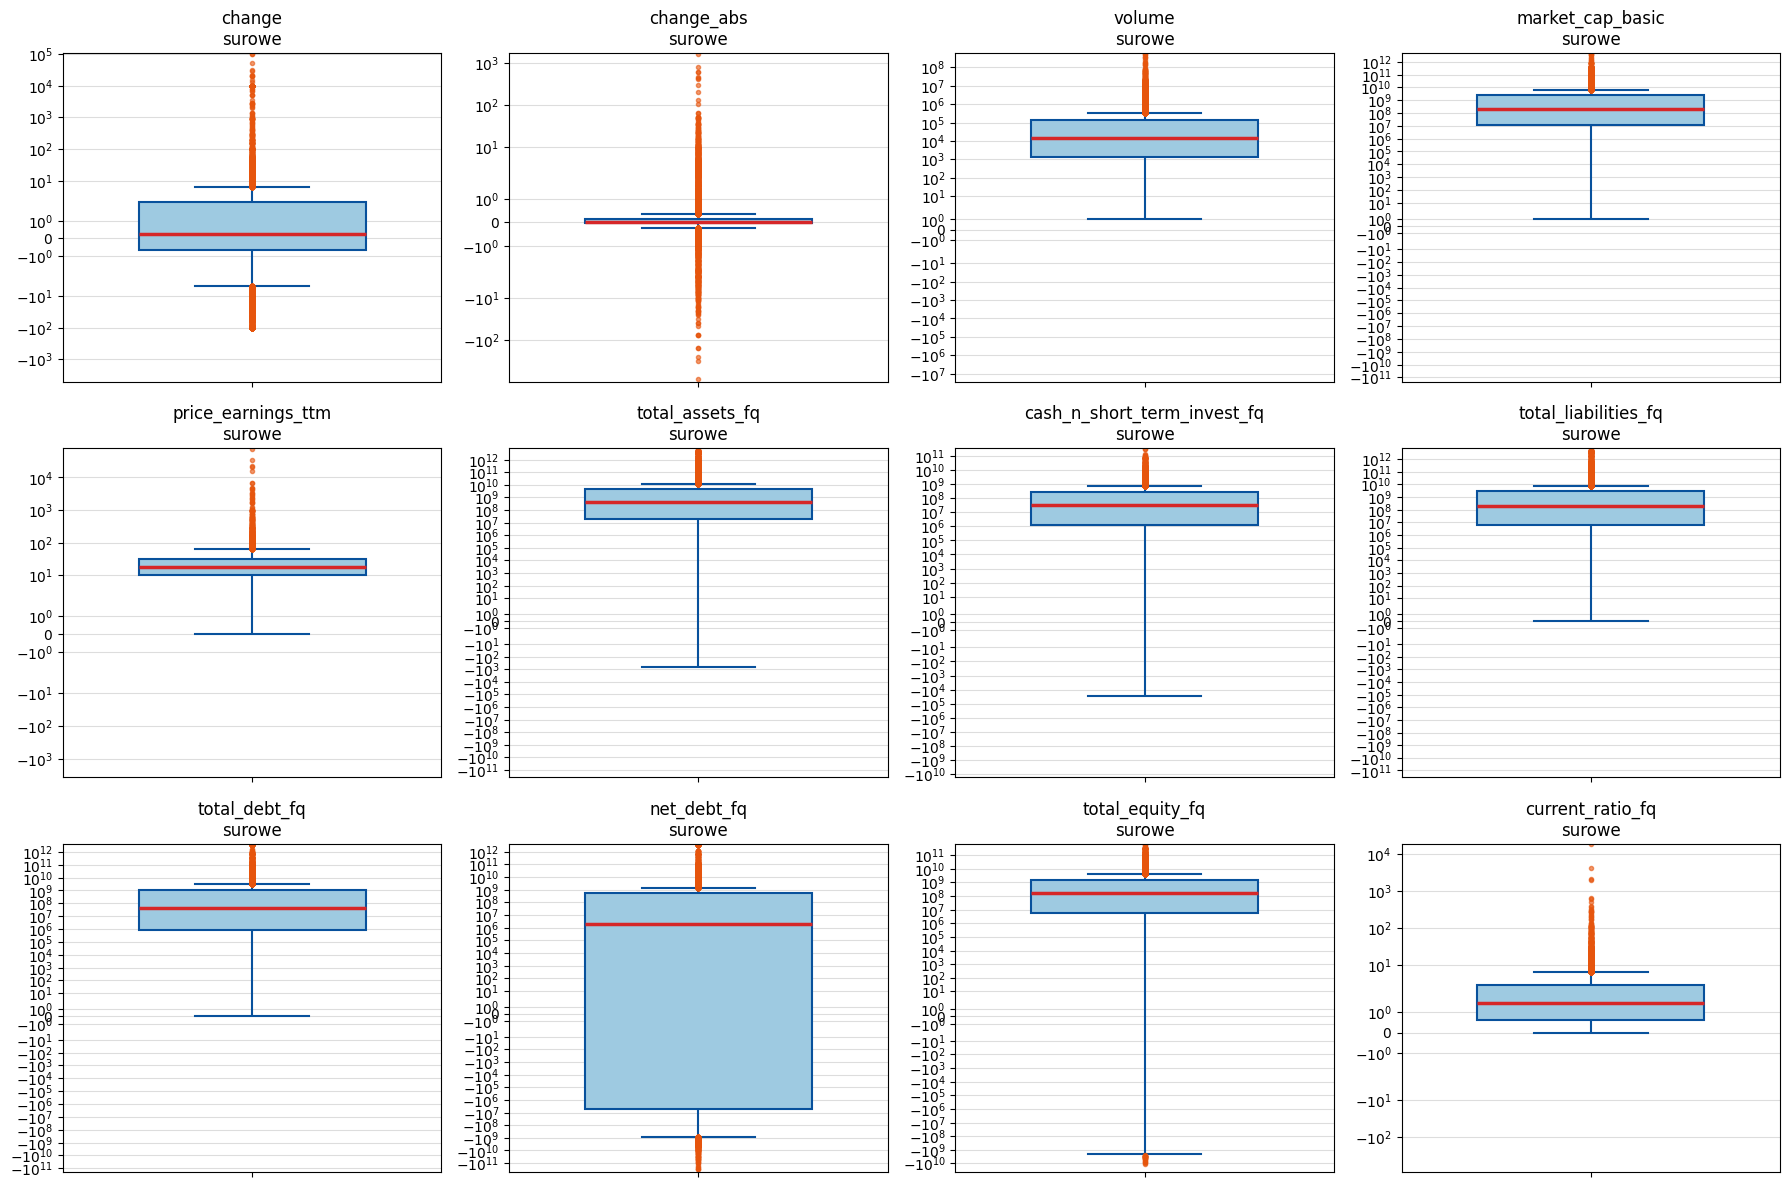

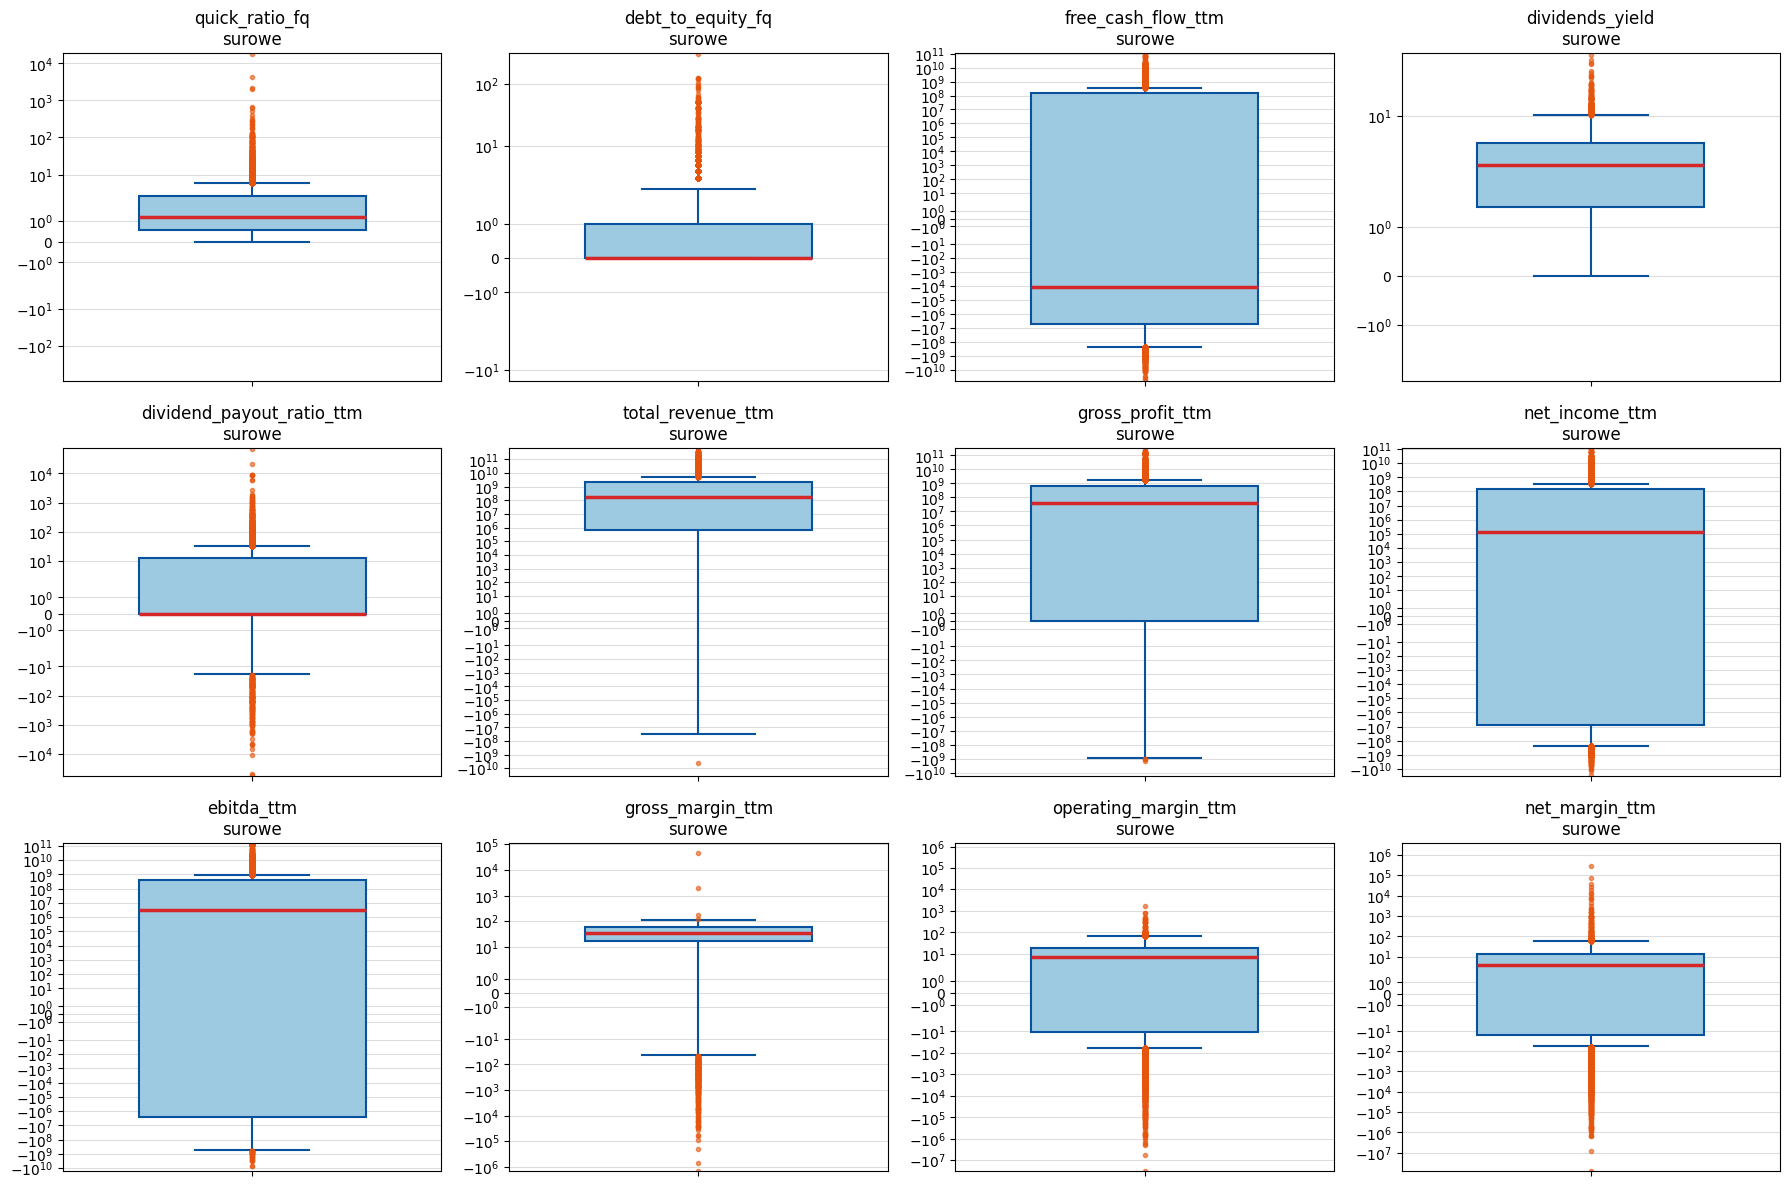

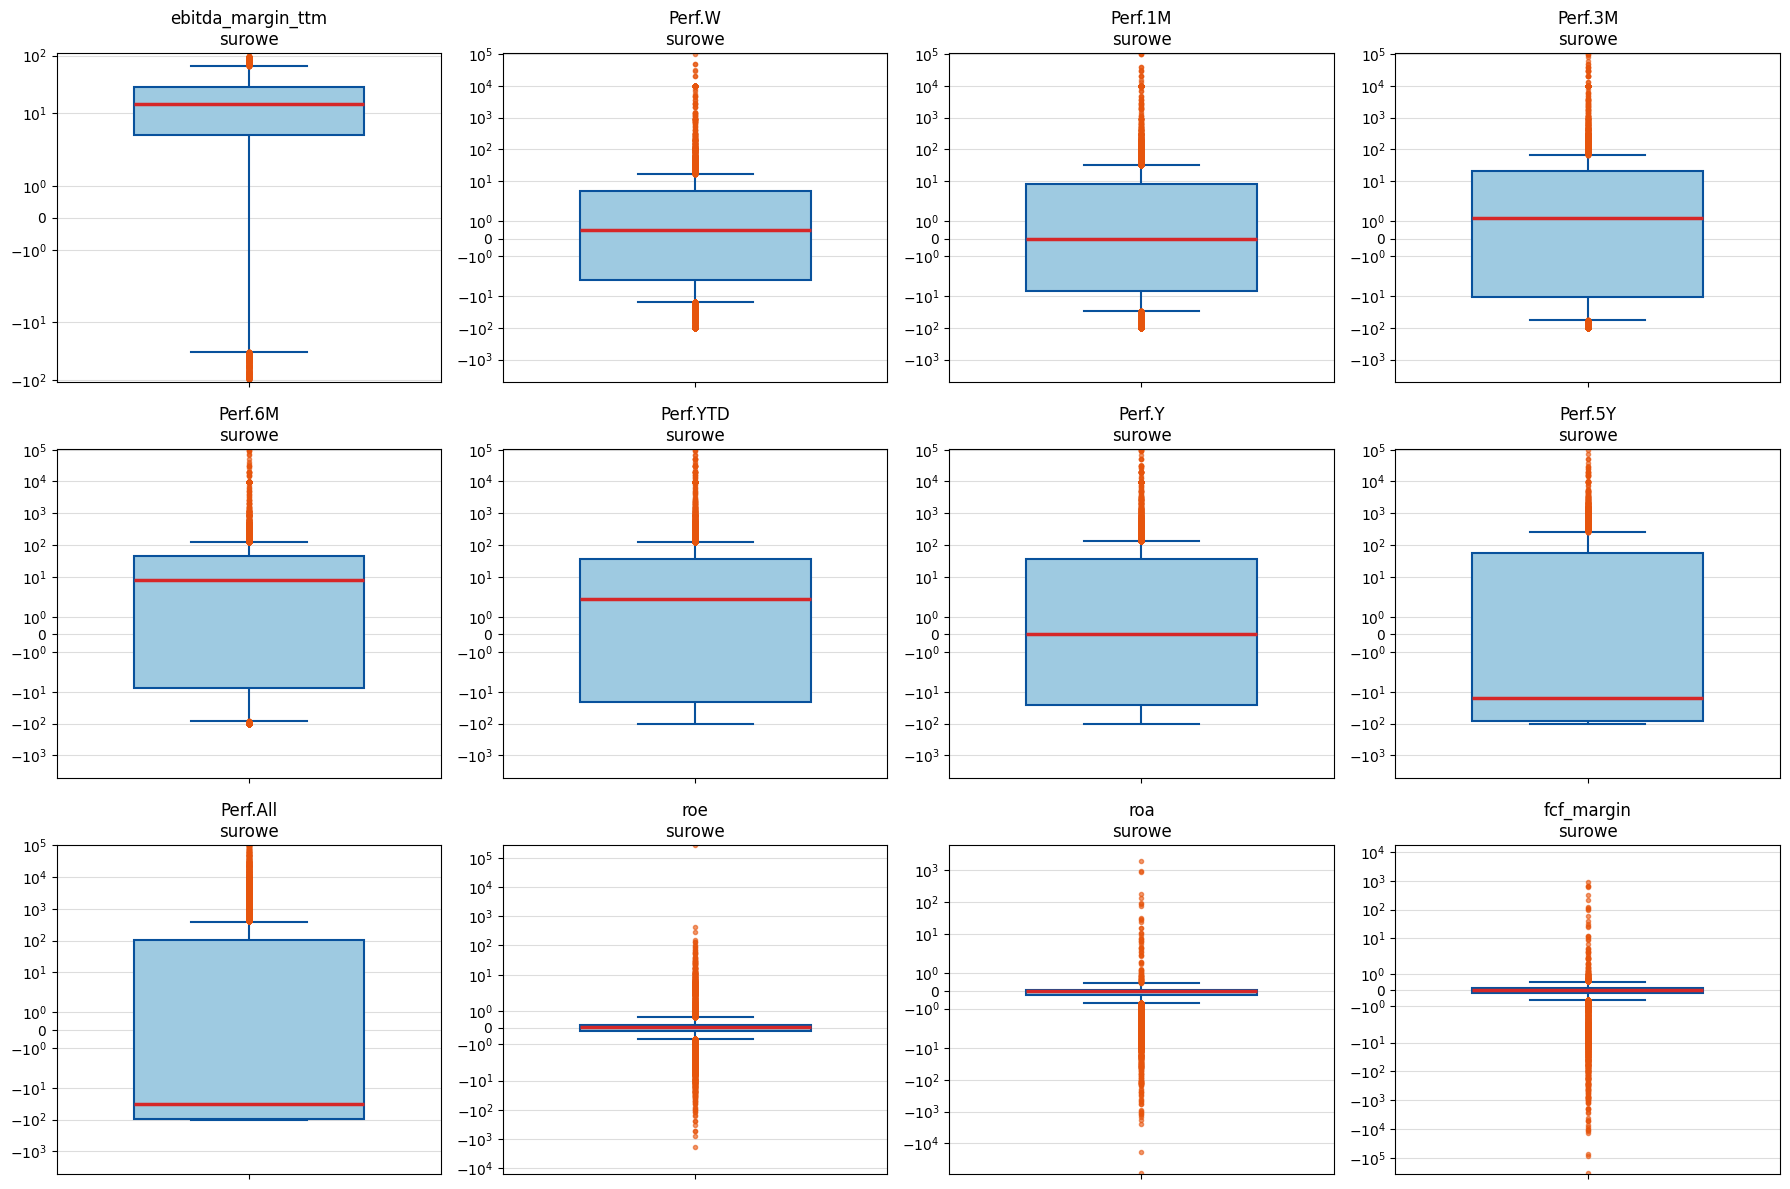

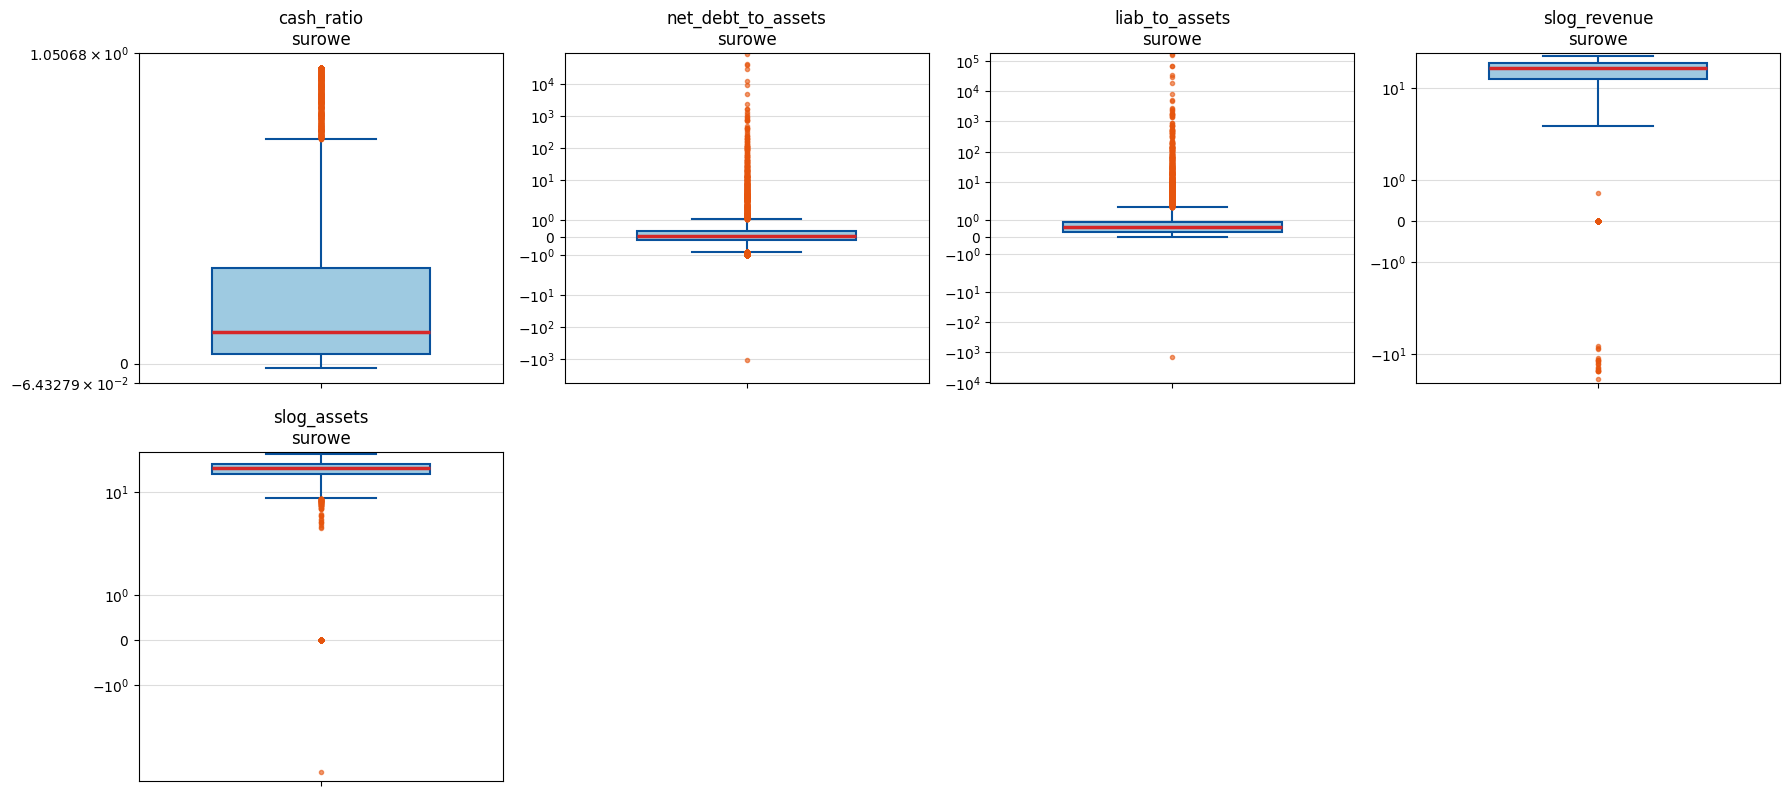

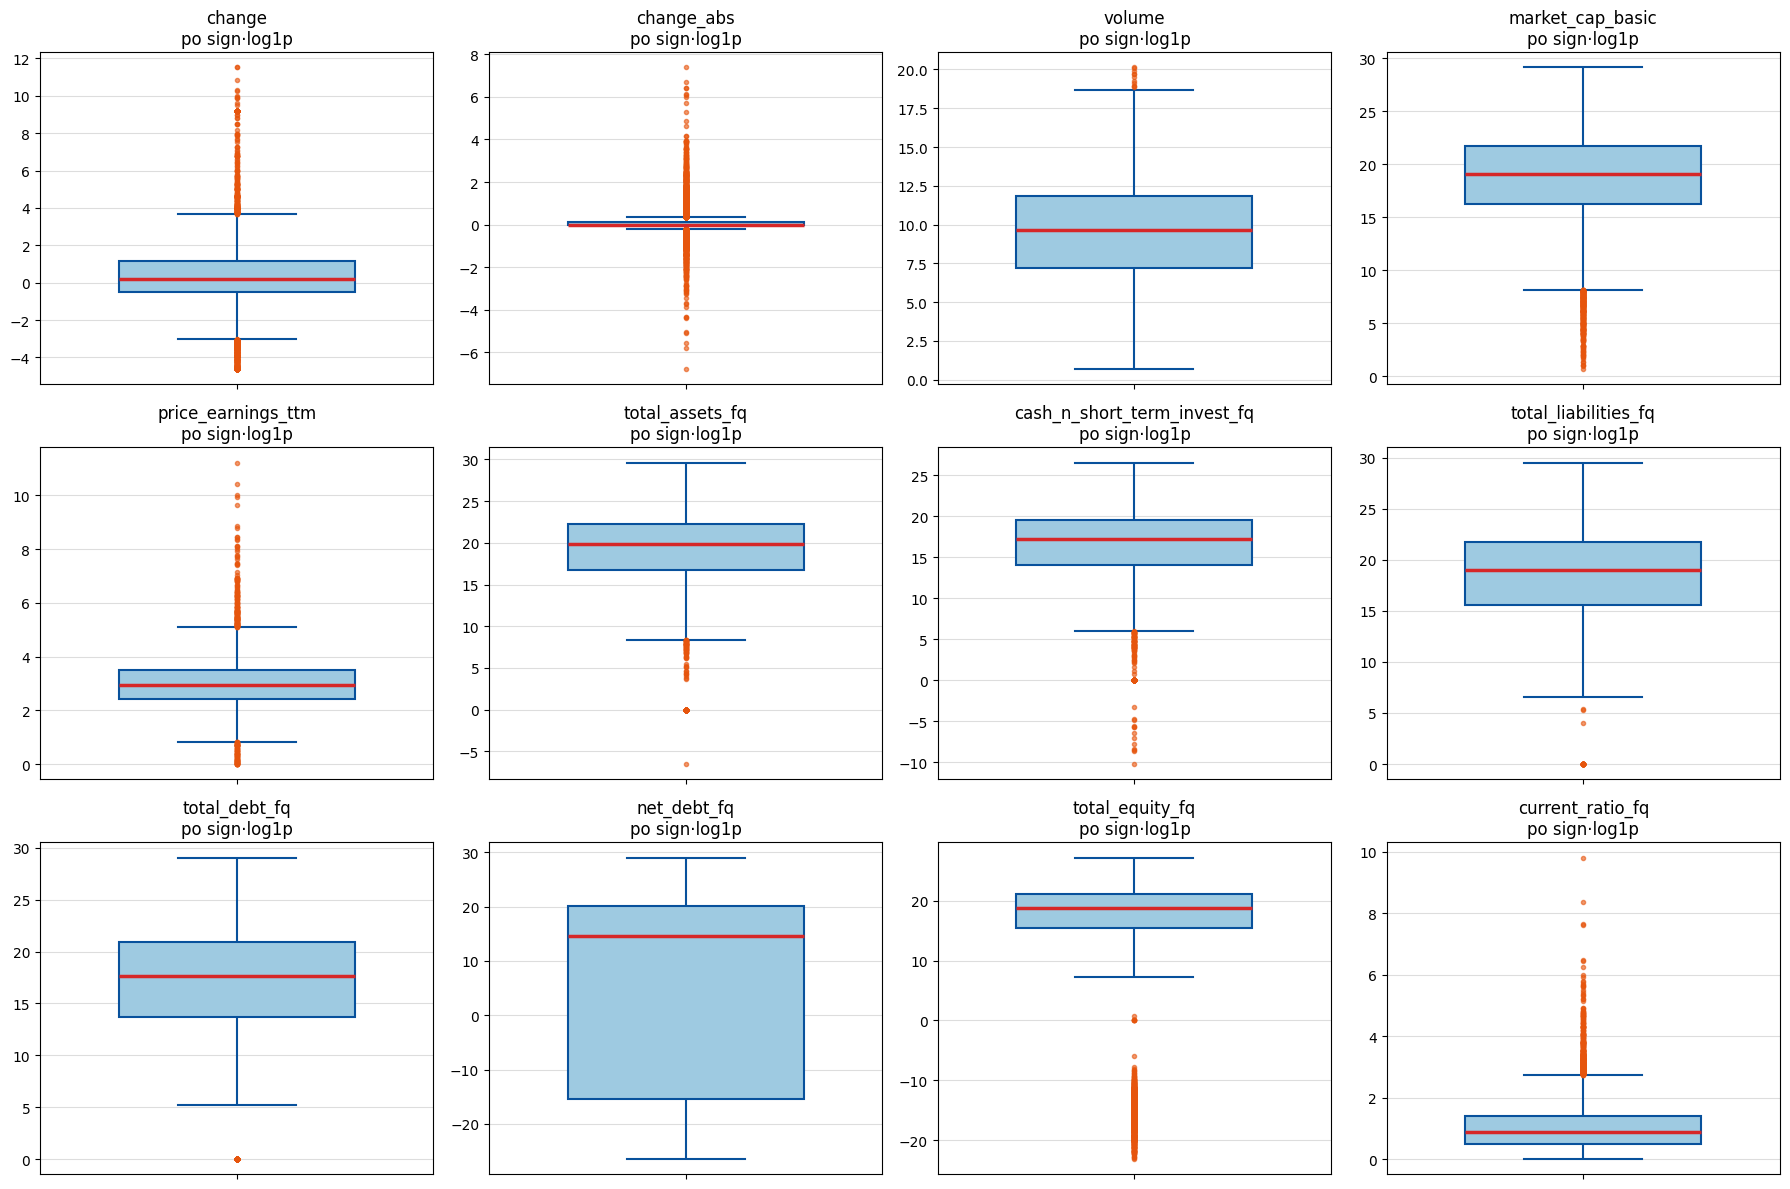

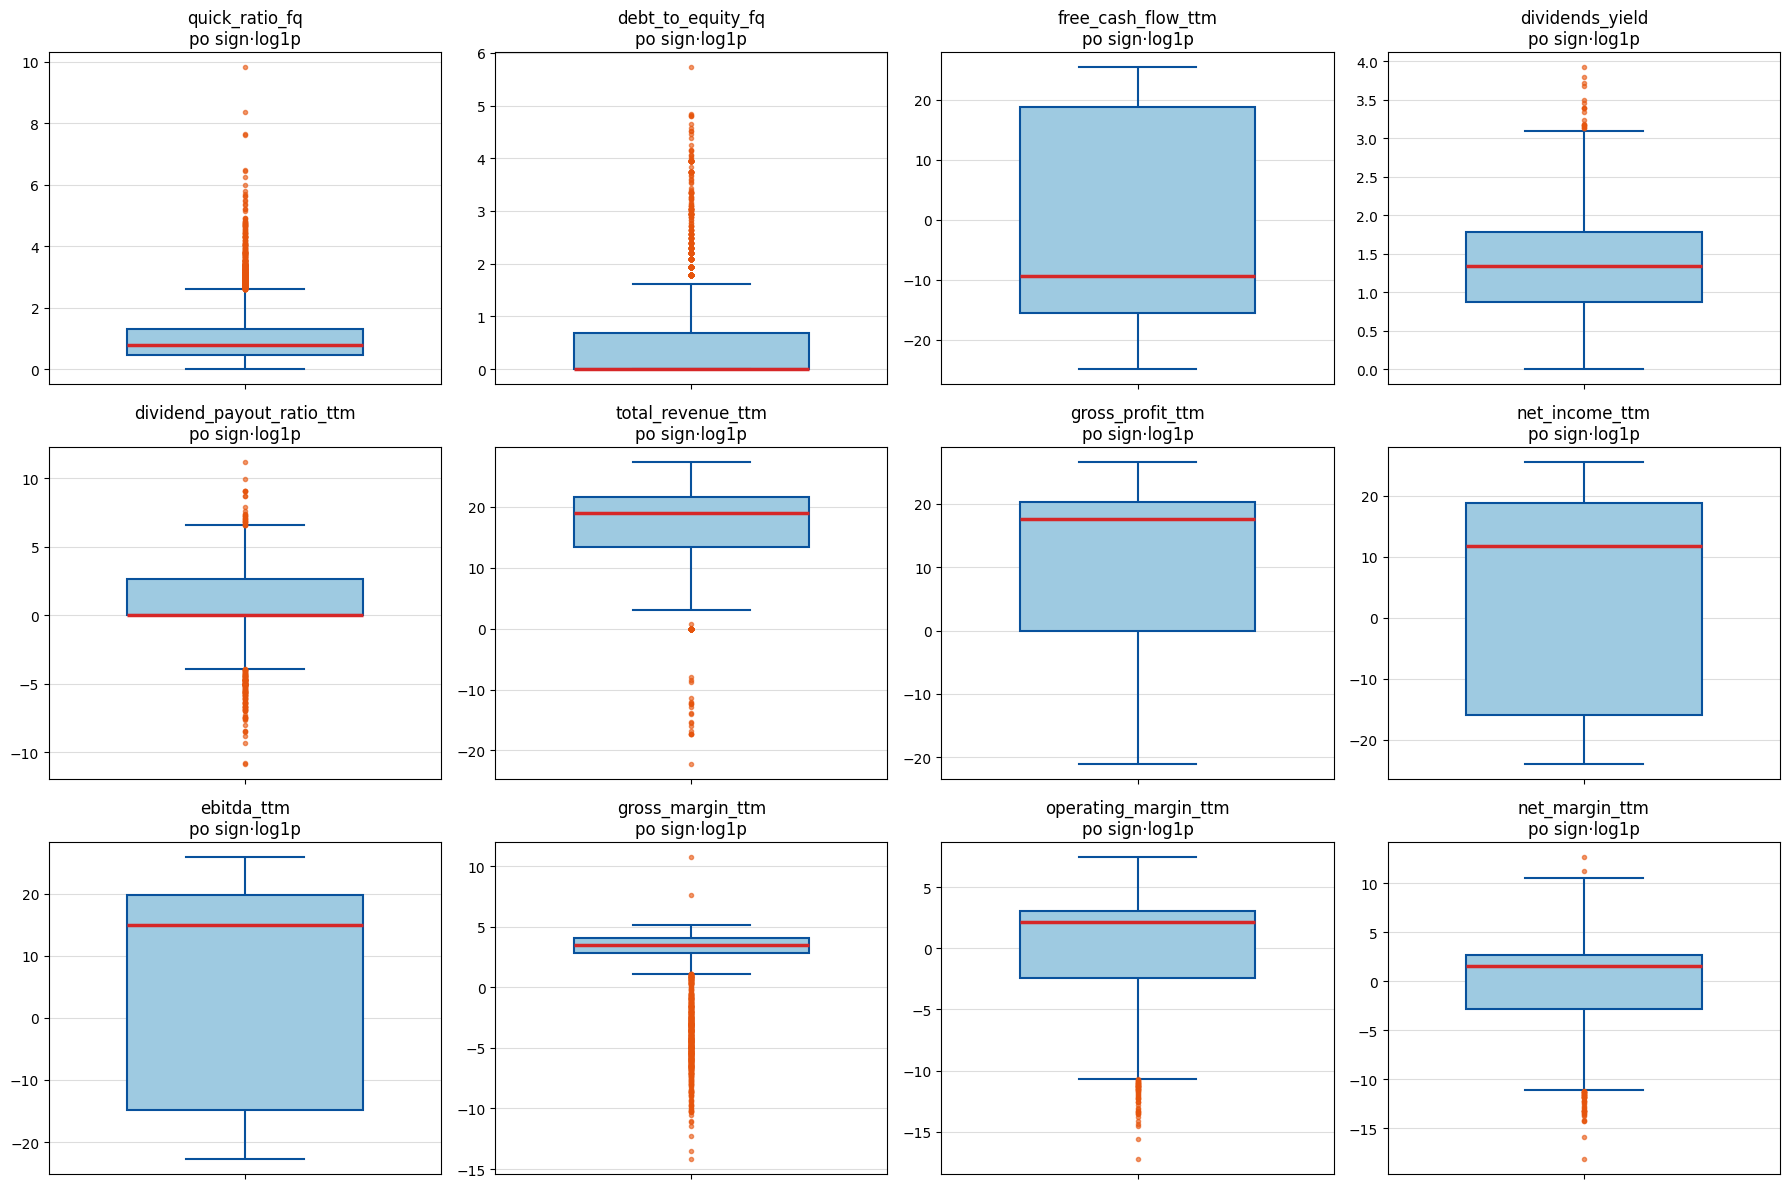

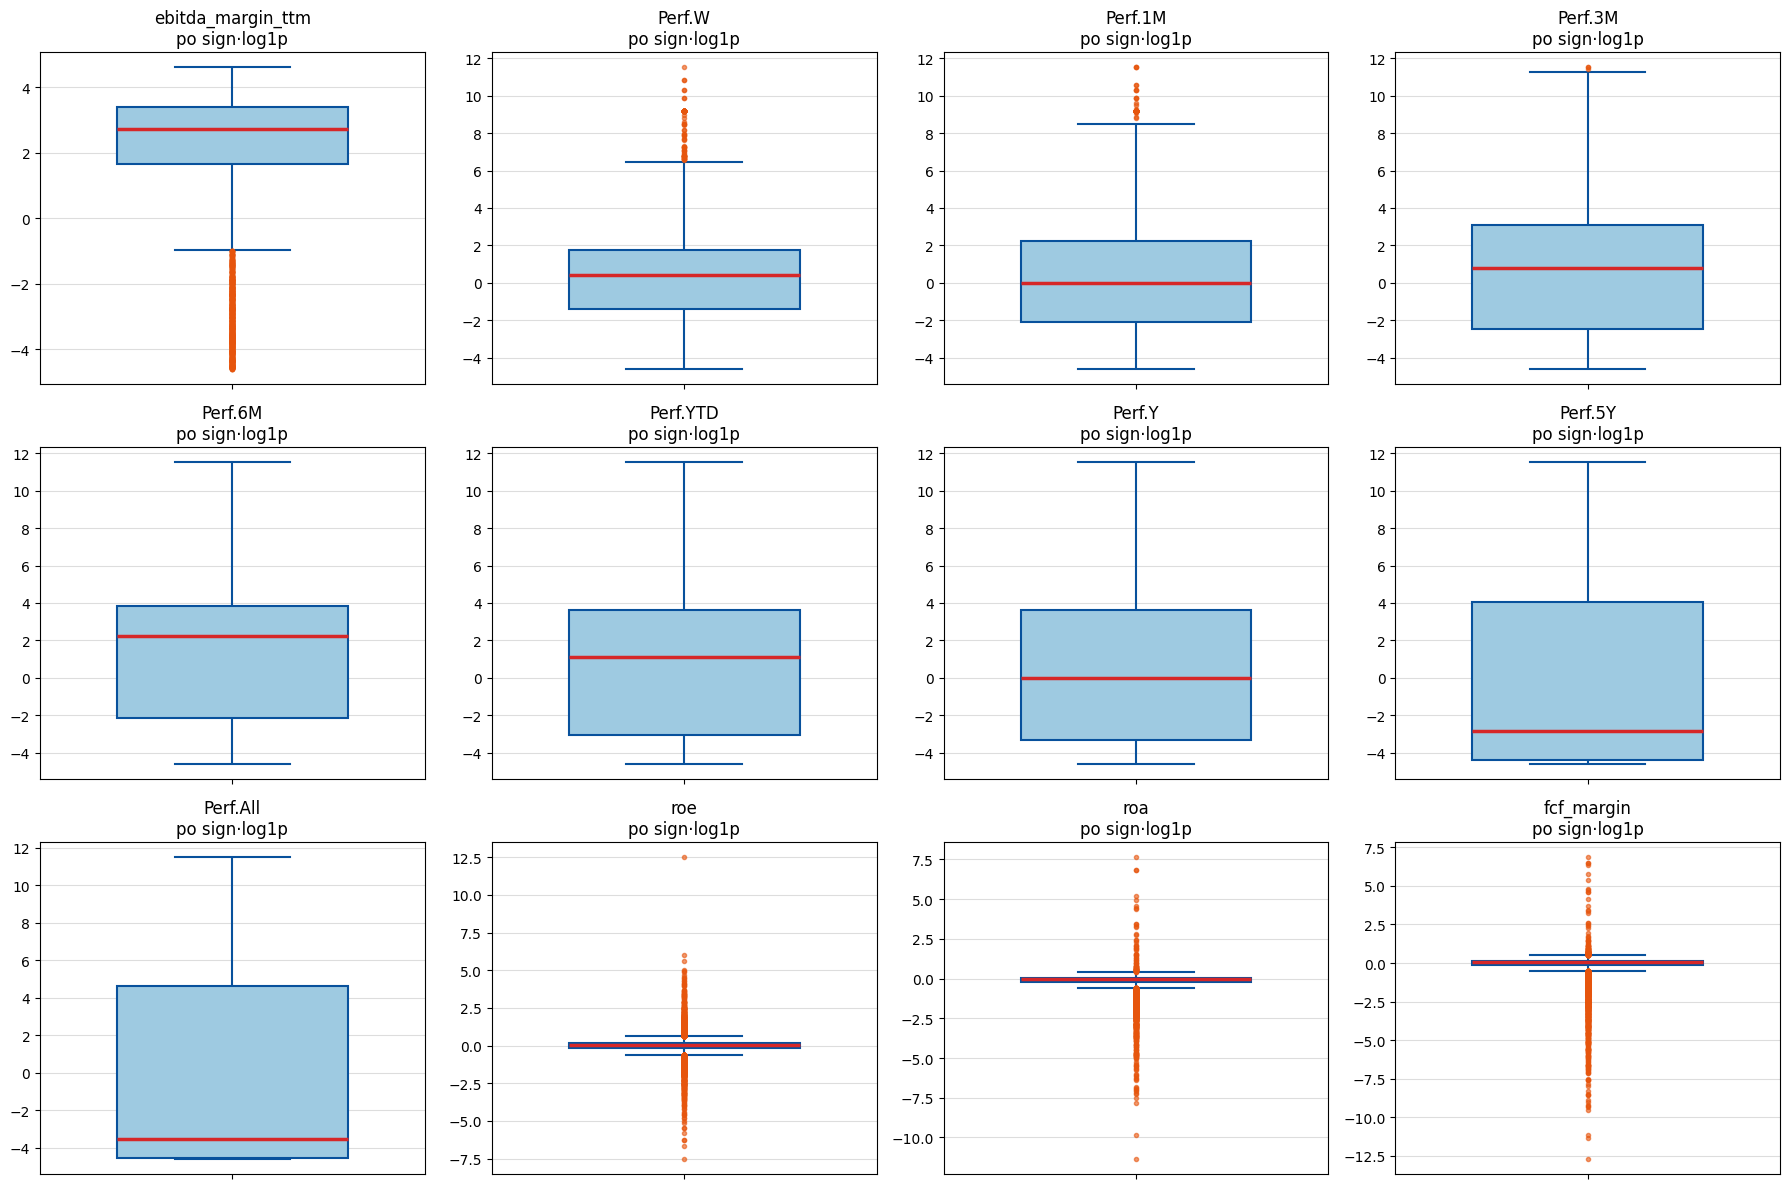

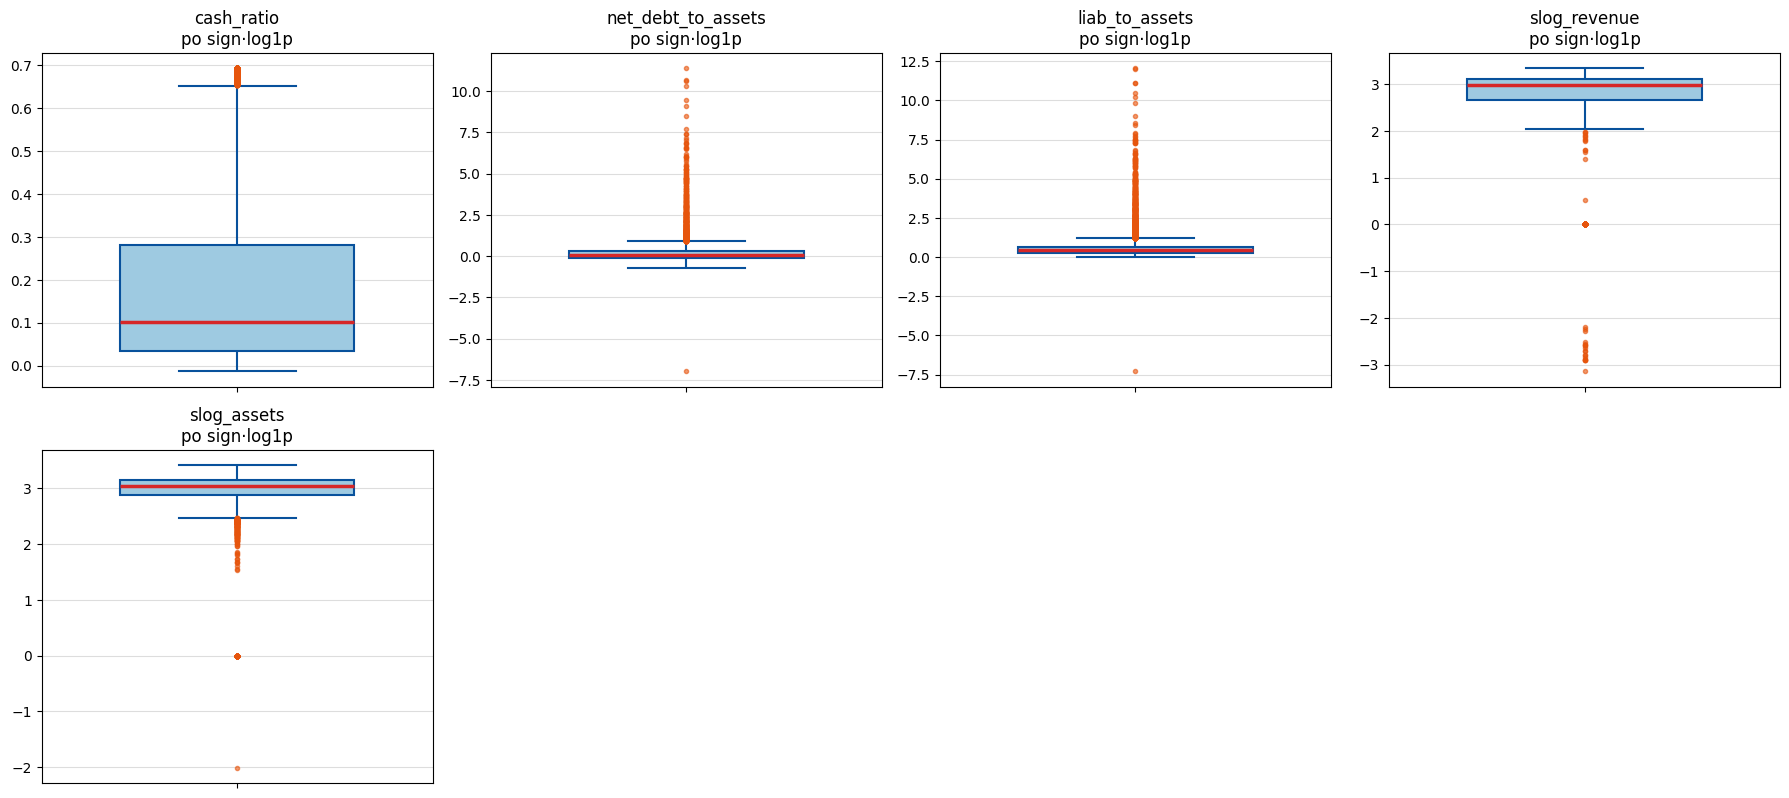

,liczba wartości,odstające (surowe),% odstających (surowe),odstające (po log),% odstających (po log)
change,11655,2516,21.600,753,6.500
change_abs,11659,2835,24.300,2695,23.100
volume,11675,1814,15.500,11,0.100
market_cap_basic,11332,1936,17.100,363,3.200
price_earnings_ttm,4697,517,11.000,280,6.000
total_assets_fq,9966,1638,16.400,115,1.200
cash_n_short_term_invest_fq,8999,1343,14.900,271,3.000
total_liabilities_fq,9912,1662,16.800,26,0.300
total_debt_fq,9935,1727,17.400,1185,11.900
net_debt_fq,9913,2196,22.200,0,0.000


In [207]:
plt.style.use("default")
NUM_ALL = list(NUM)

def box_batches(get_values, symlog, label):
    # box-ploty w partiach po 12 kolumn (3 wiersze × 4), żeby każdy był czytelny
    for start in range(0, len(NUM_ALL), 12):
        batch = NUM_ALL[start:start + 12]
        fig, axes = plt.subplots(3, 4, figsize=(18, 12))
        for ax, c in zip(axes.ravel(), batch):
            sns.boxplot(
                y=get_values(c), ax=ax, width=0.6,
                boxprops=dict(facecolor="#9ecae1", edgecolor="#08519c", linewidth=1.5),
                whiskerprops=dict(color="#08519c", linewidth=1.5),
                capprops=dict(color="#08519c", linewidth=1.5),
                medianprops=dict(color="#d62728", linewidth=2.5),
                flierprops=dict(marker="o", markerfacecolor="#e6550d", markeredgecolor="#e6550d", markersize=3, alpha=0.6),
            )
            if symlog:
                ax.set_yscale("symlog")
            ax.set_title(f"{c}\n{label}")
            ax.set_ylabel("")
            ax.grid(axis="y", color="#dddddd")
        for ax in axes.ravel()[len(batch):]:
            ax.set_visible(False)
        plt.tight_layout()
        plt.show()

def iqr_outliers(s):
    # wartości poza 1,5 * IQR od kwartyli
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

# 1) wartości surowe, oś symlog
box_batches(lambda c: df[c].dropna(), symlog=True, label="surowe")
# 2) te same kolumny po sign·log1p, oś liniowa
box_batches(lambda c: slog(df[c].dropna()), symlog=False, label="po sign·log1p")

outliers = pd.DataFrame({
    "liczba wartości": df[NUM_ALL].notna().sum(),
    "odstające (surowe)": [iqr_outliers(df[c].dropna()) for c in NUM_ALL],
    "% odstających (surowe)": [iqr_outliers(df[c].dropna()) / df[c].notna().sum() * 100 for c in NUM_ALL],
    "odstające (po log)": [iqr_outliers(slog(df[c].dropna())) for c in NUM_ALL],
    "% odstających (po log)": [iqr_outliers(slog(df[c].dropna())) / df[c].notna().sum() * 100 for c in NUM_ALL],
}, index=NUM_ALL)
display(outliers.round(1))

**Wnioski z box-plotów:**
- **Kwoty w pieniądzach** (aktywa, zobowiązania, kapitał, przychody, zysk, EBITDA, kapitalizacja, obrót): surowo pudełko leży w dolnej części skali, a kropki sięgają bardzo wysoko. Po logarytmie większość pudełek mieści się w rozsądnym zakresie. Pudełka pozostają szerokie dla `net_debt_fq`, `free_cash_flow_ttm`, `net_income_ttm`, `ebitda_ttm` i `gross_profit_ttm`, bo mieszają zyski i straty.
- **Mediana przy zerze:** `dividend_payout_ratio_ttm` i `debt_to_equity_fq`. Dolna krawędź pudełka `gross_profit_ttm` też leży przy zerze.
- **Ruch ceny** (`change`, `change_abs`, `Perf.*`): pudełka przy zerze, kropki do ekstremów po obu stronach. `change_abs` ma najwięcej kropek ze wszystkich kolumn (ok. 24% surowo), `change` ok. 22%.
- **Wskaźniki w procentach** (marże, `roe`, `roa`, `fcf_margin`, `net_debt_to_assets`, `liab_to_assets`): mediana blisko zera, wąskie pudełka, kropki po obu stronach. Surowo kropek jest ok. 15–21% (`roe` 21%, `fcf_margin` 20%, `roa` 15%).
- **Pozostałe kolumny z dużą liczbą kropek surowo:** `net_debt_fq` (22%), `net_income_ttm` i `free_cash_flow_ttm` (po 21%), `market_cap_basic` (17%), `total_assets_fq` i `total_equity_fq` (po 16%).
- **Po logarytmie najwięcej kropek:** `change_abs` (ok. 23%), `slog_revenue` (ok. 20%), `total_revenue_ttm` (ok. 20%), `ebitda_margin_ttm` (ok. 17%), `roe` (ok. 17%).
- **Po logarytmie bez kropek:** `net_debt_fq`. Najmniej kropek mają `volume` po logarytmie (prawie zero) i `slog_assets` surowo (ok. 1%).

### 2d. Histogramy i transformacje log

Histogram pokazuje, ile spółek ma wartość w danym przedziale. Wyższy słupek oznacza więcej spółek.

- **Skośność:** liczba opisująca asymetrię rozkładu. Wartość około 0 oznacza rozkład symetryczny. Dodatnia oznacza długi ogon w prawo: większość spółek ma małe wartości, kilka bardzo duże. Ujemna oznacza długi ogon w lewo.
- **Wpływ na model:** kilka ekstremalnych wartości potrafi zdominować dopasowanie, bo model minimalizuje błędy kwadratowe.
- **Logarytm `sign·log1p`:** ściska duże wartości, rozciąga małe i zachowuje znak. Kształt rozkładu widać nawet wtedy, gdy surowa skala jest zdominowana przez kilka skrajnych wartości.

Wykresy są w dwóch wersjach: 41 kolumn surowo (niebieskie) i 41 po logarytmie (pomarańczowe). Tabela pod wykresami podaje skośność przed i po przekształceniu.

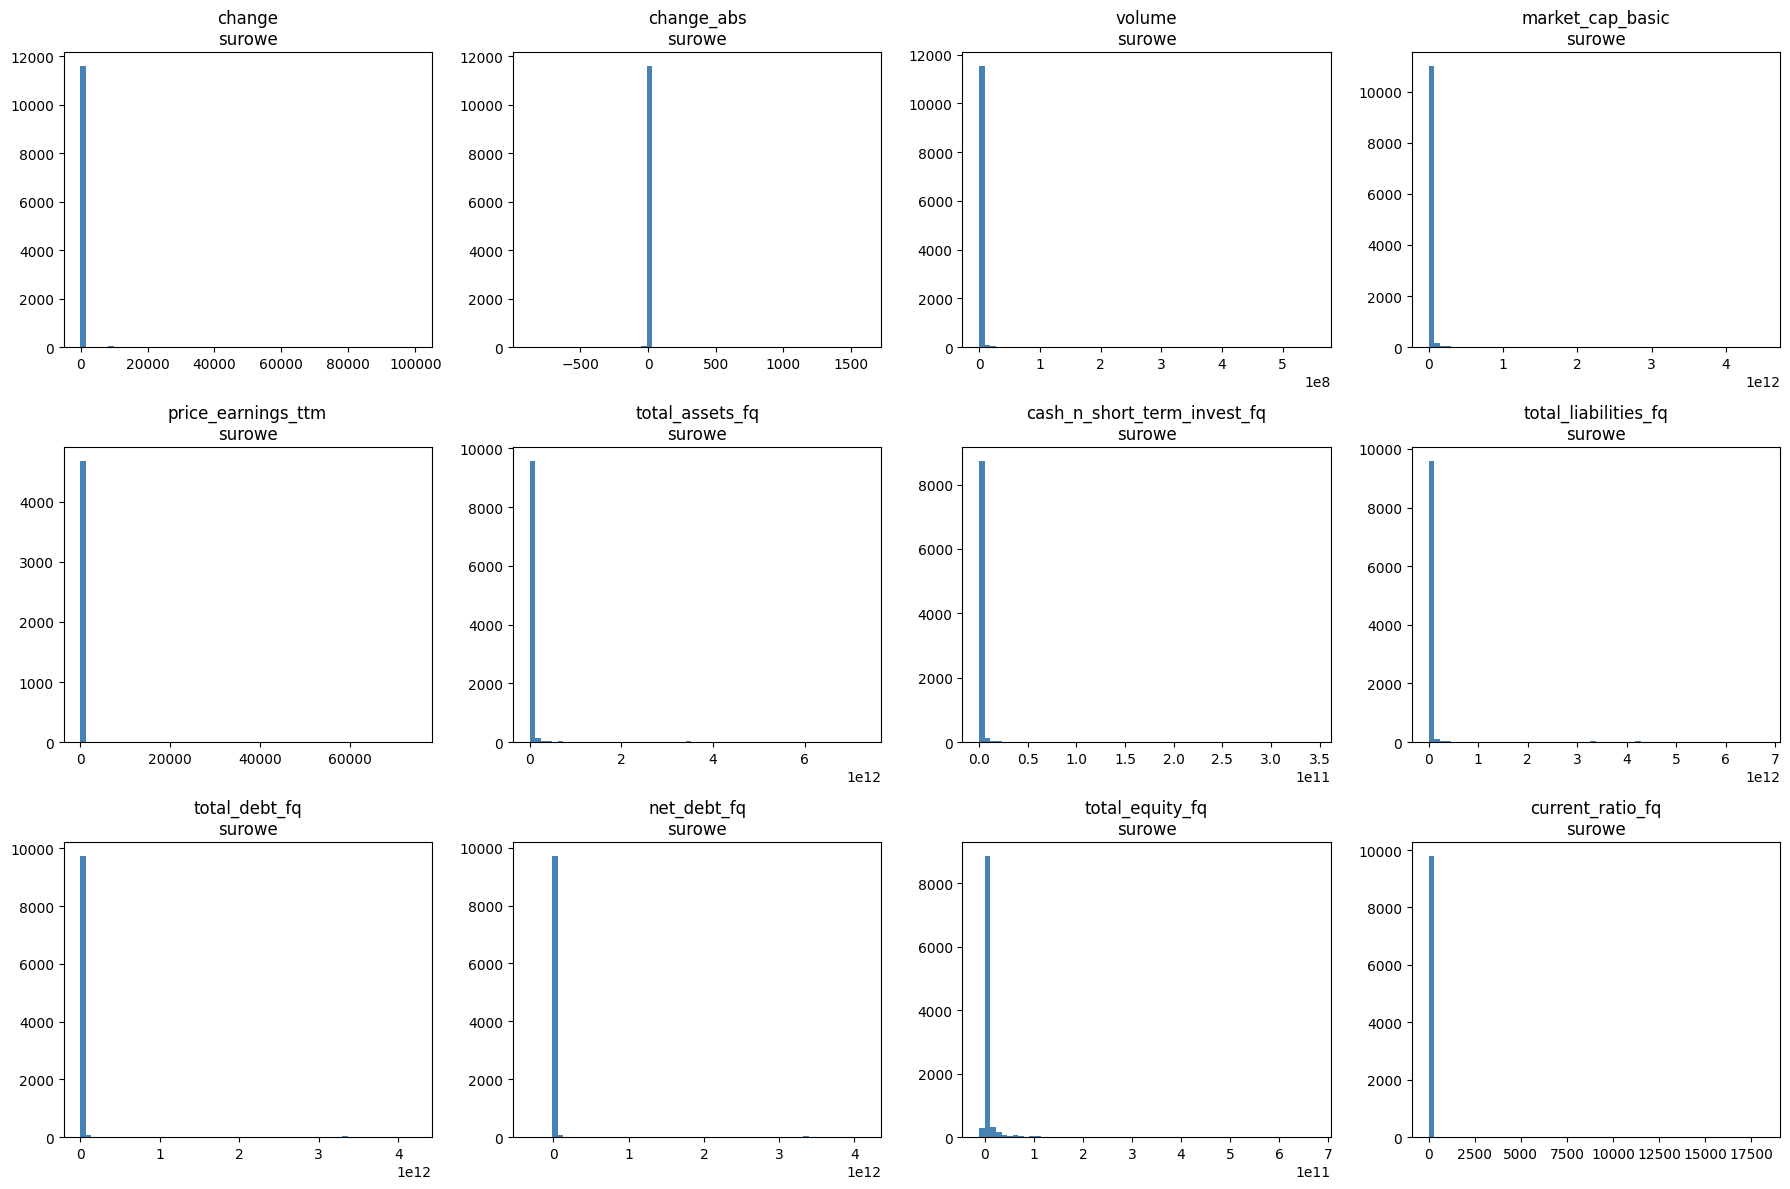

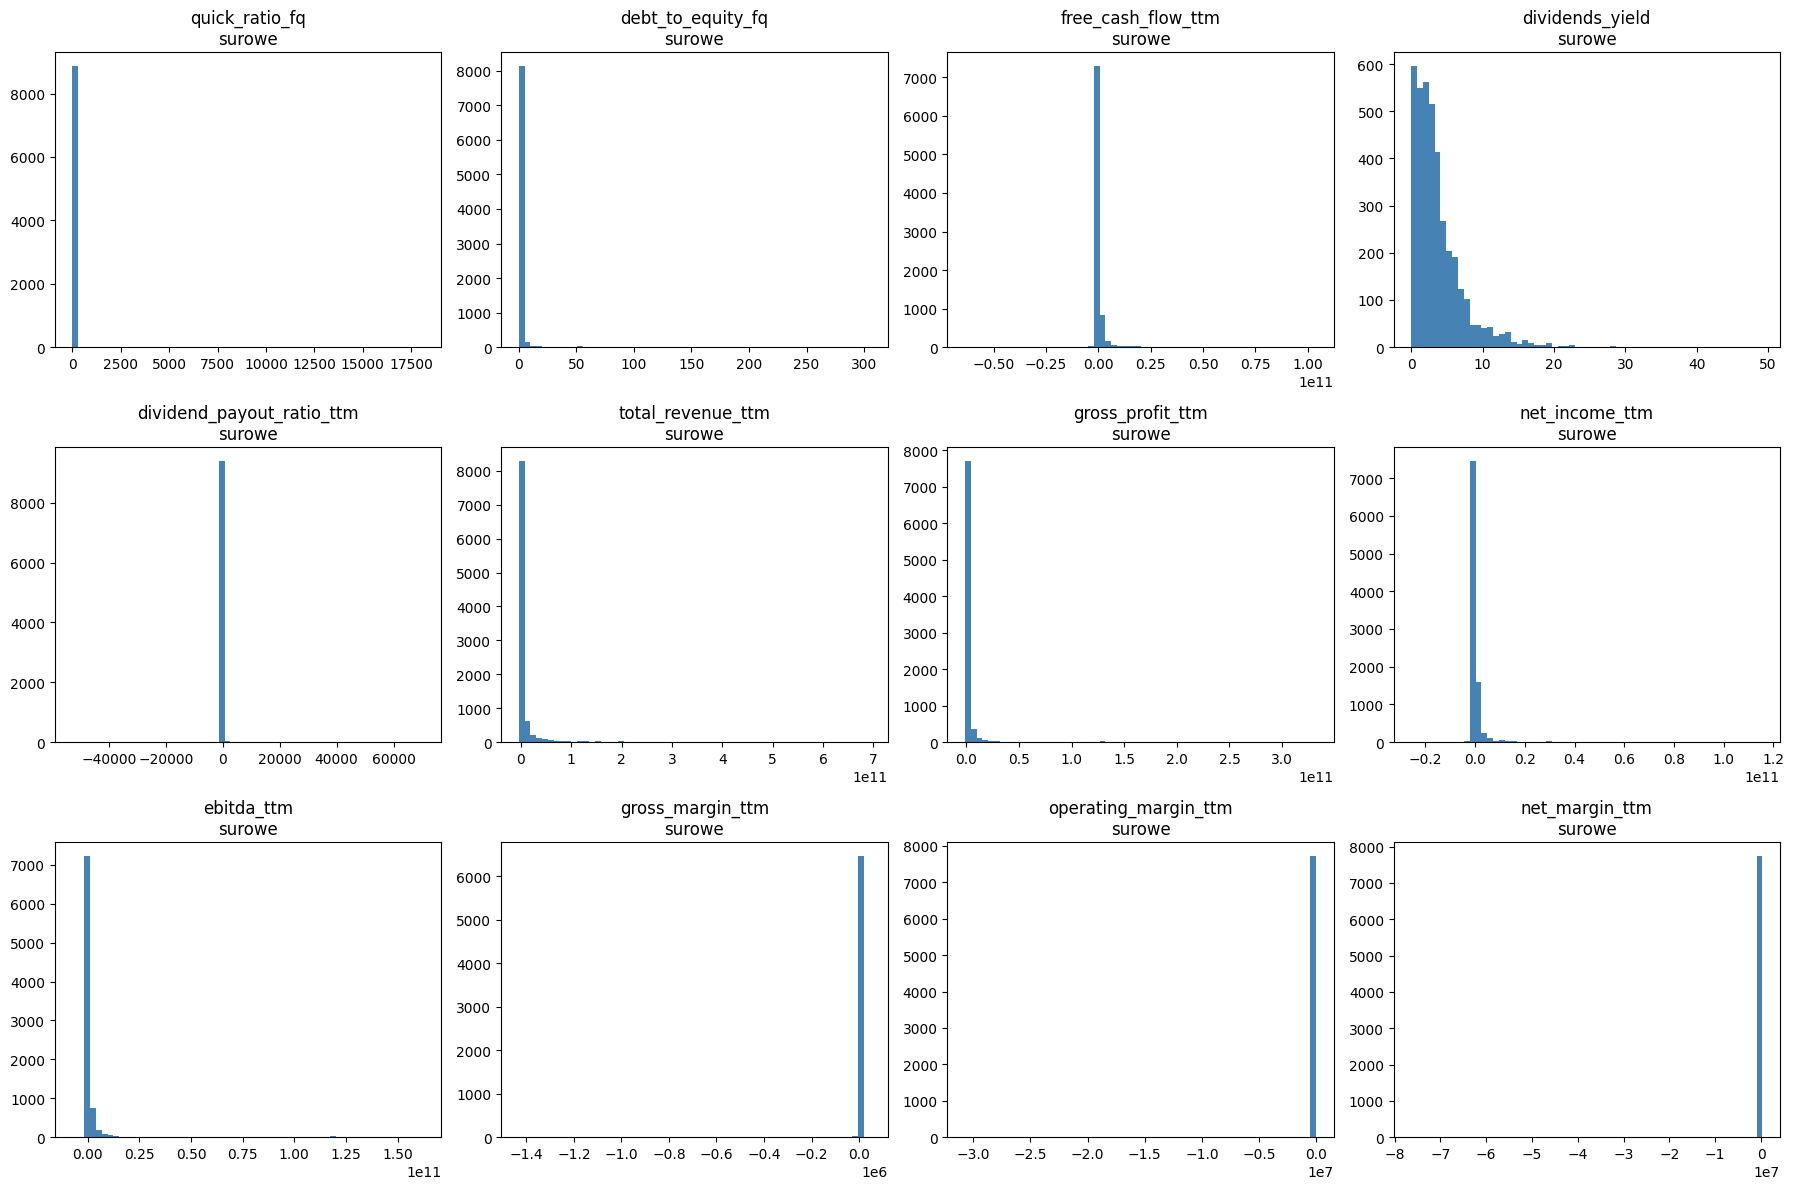

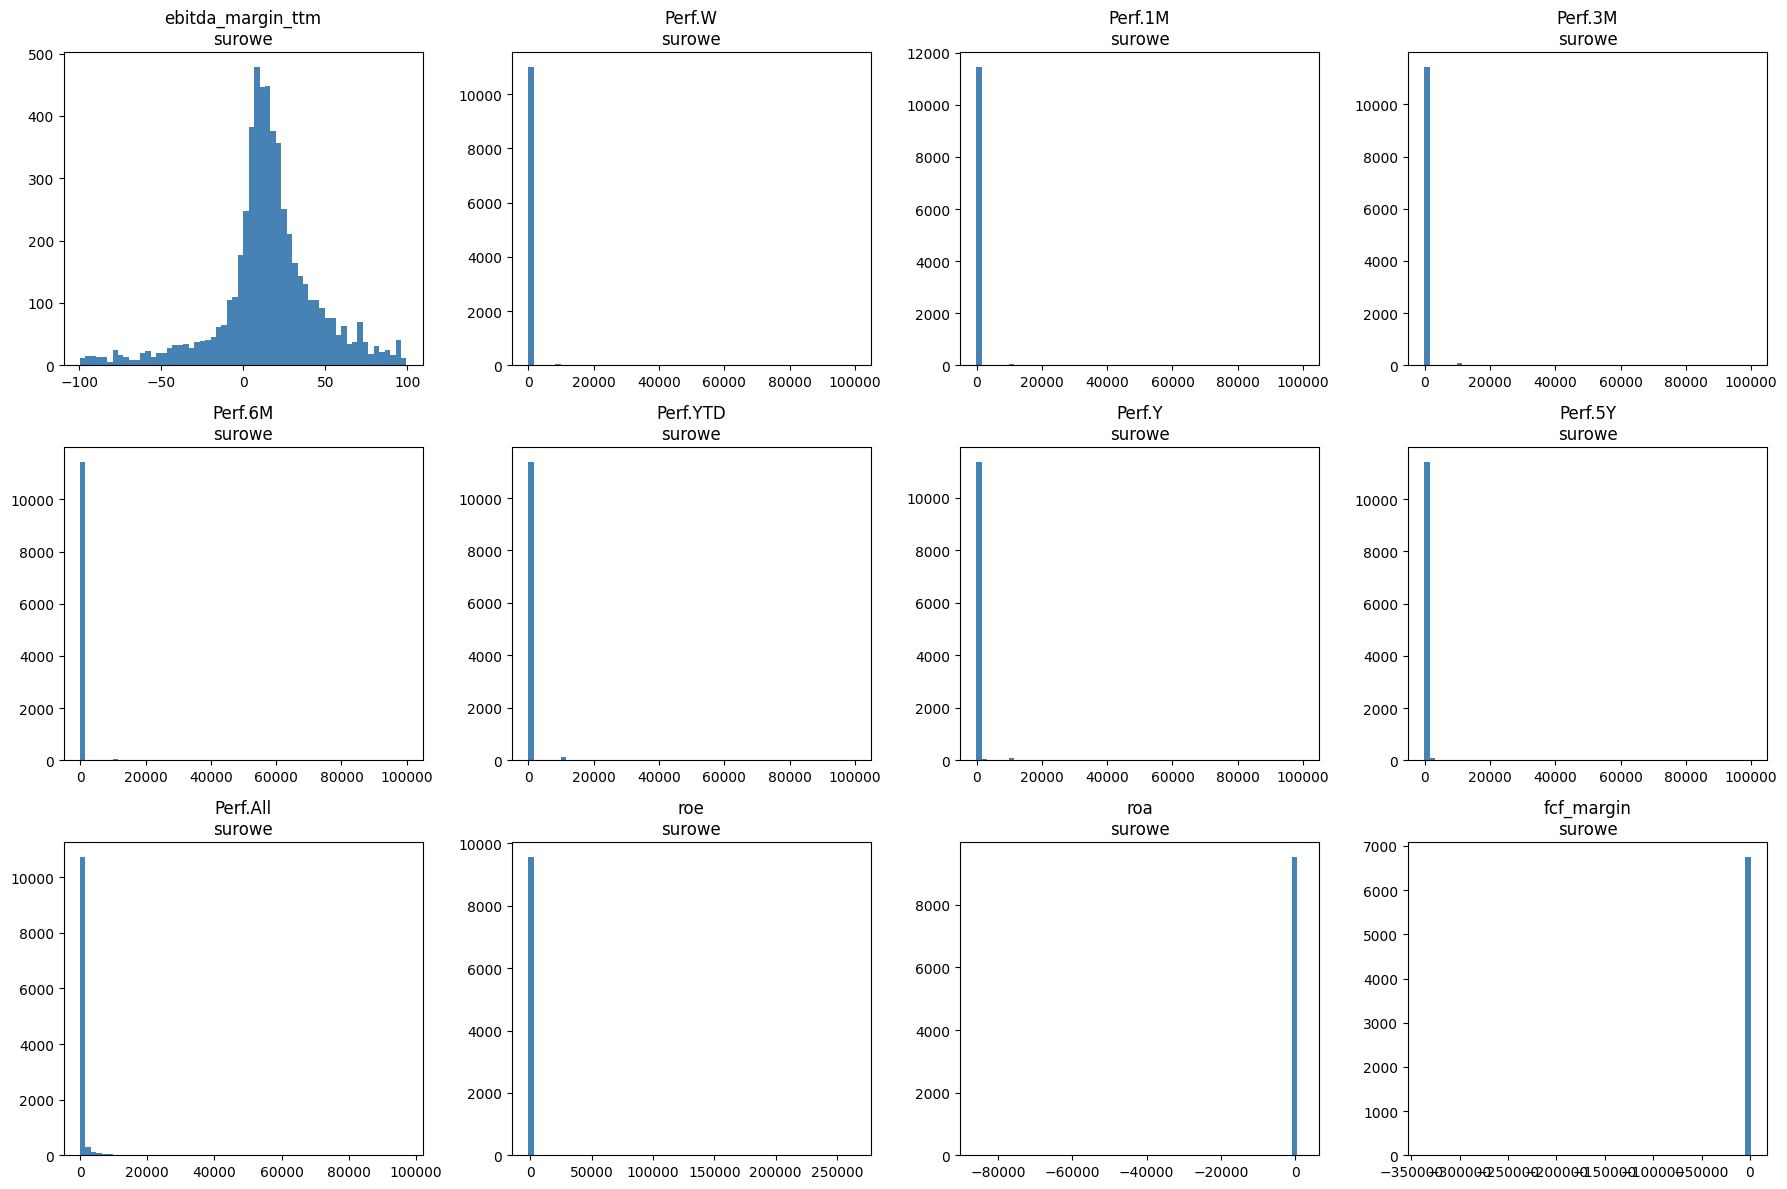

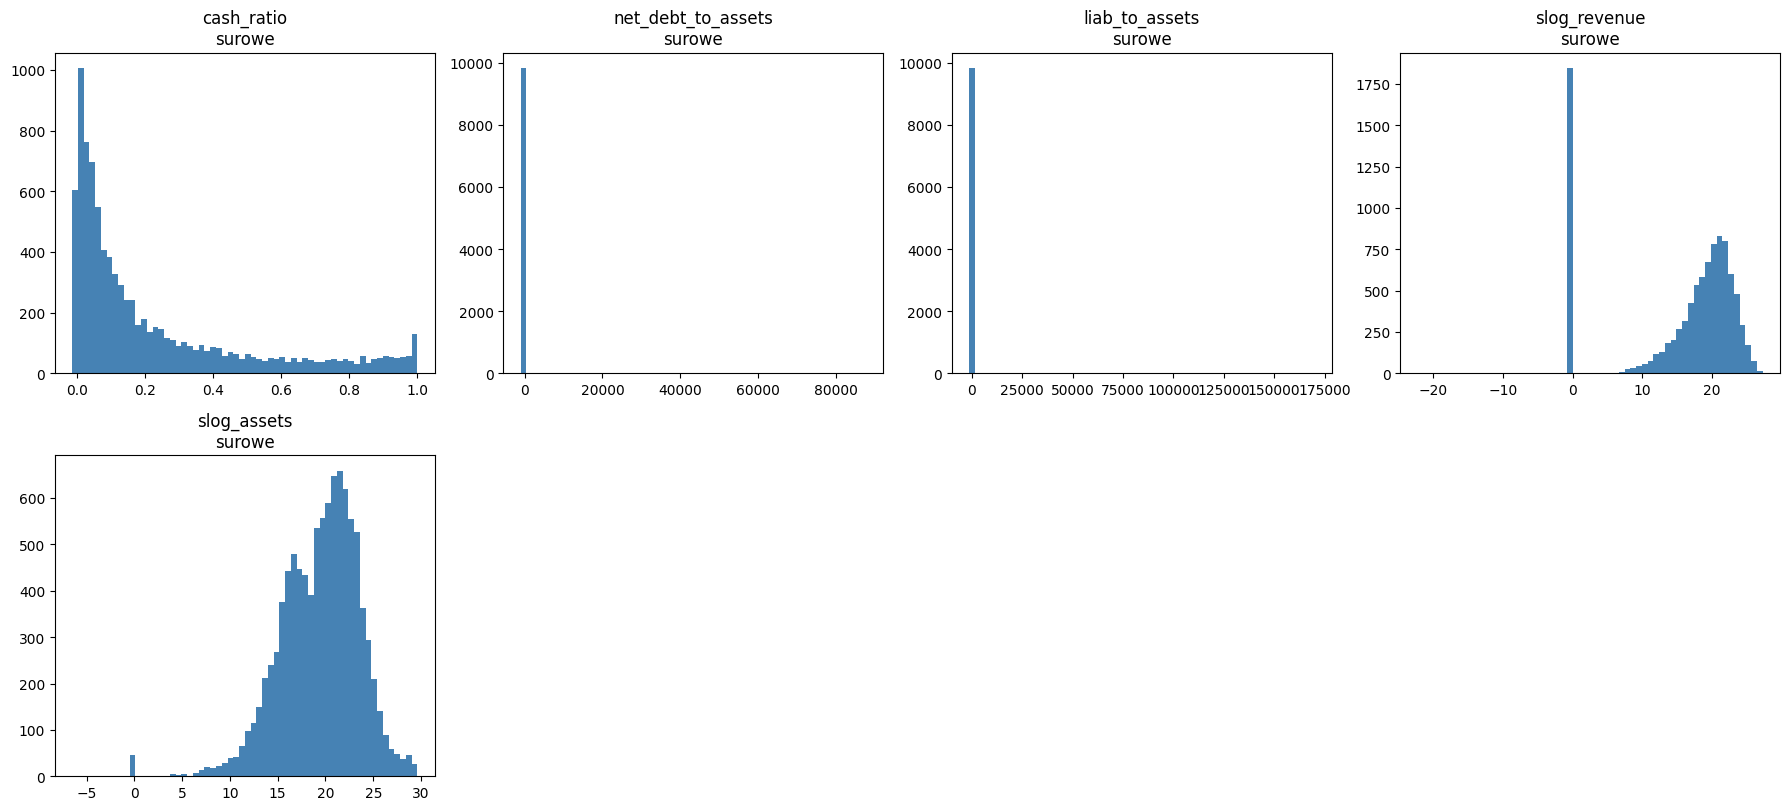

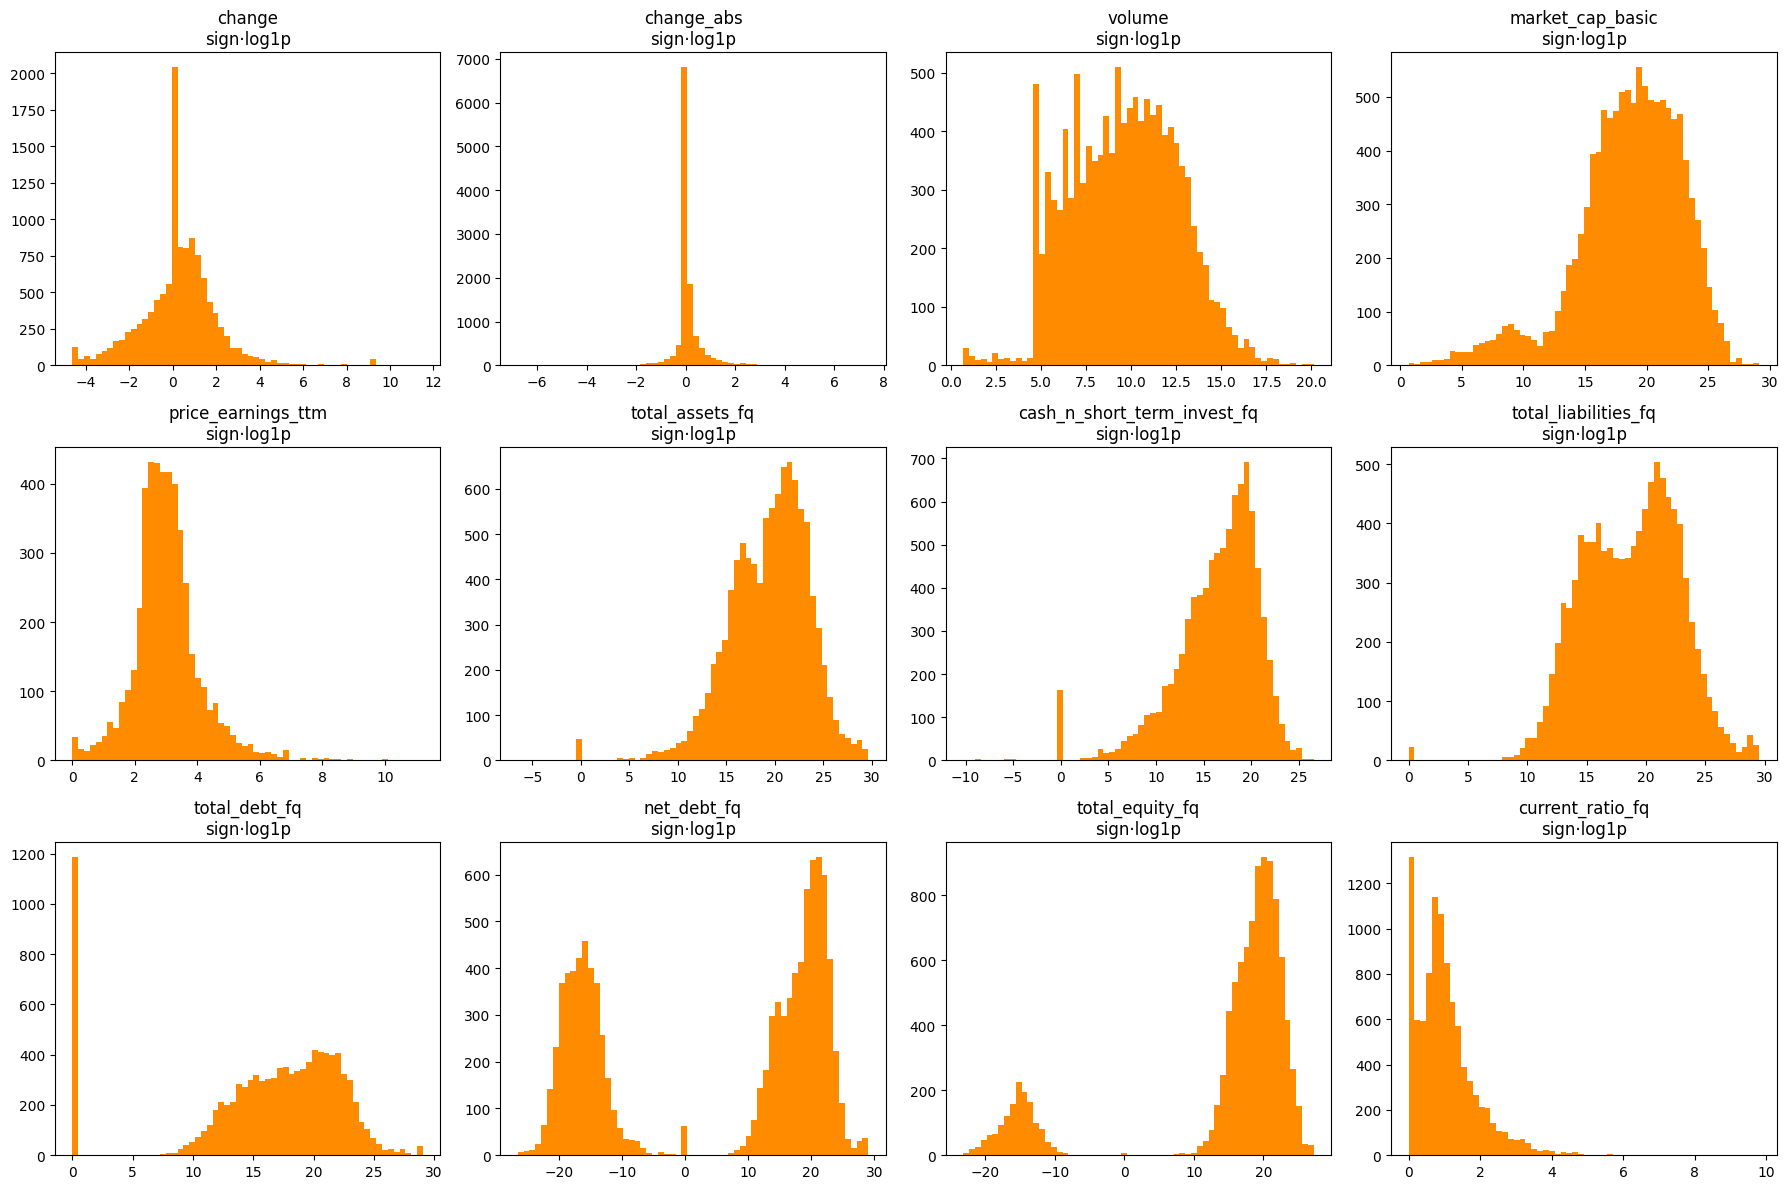

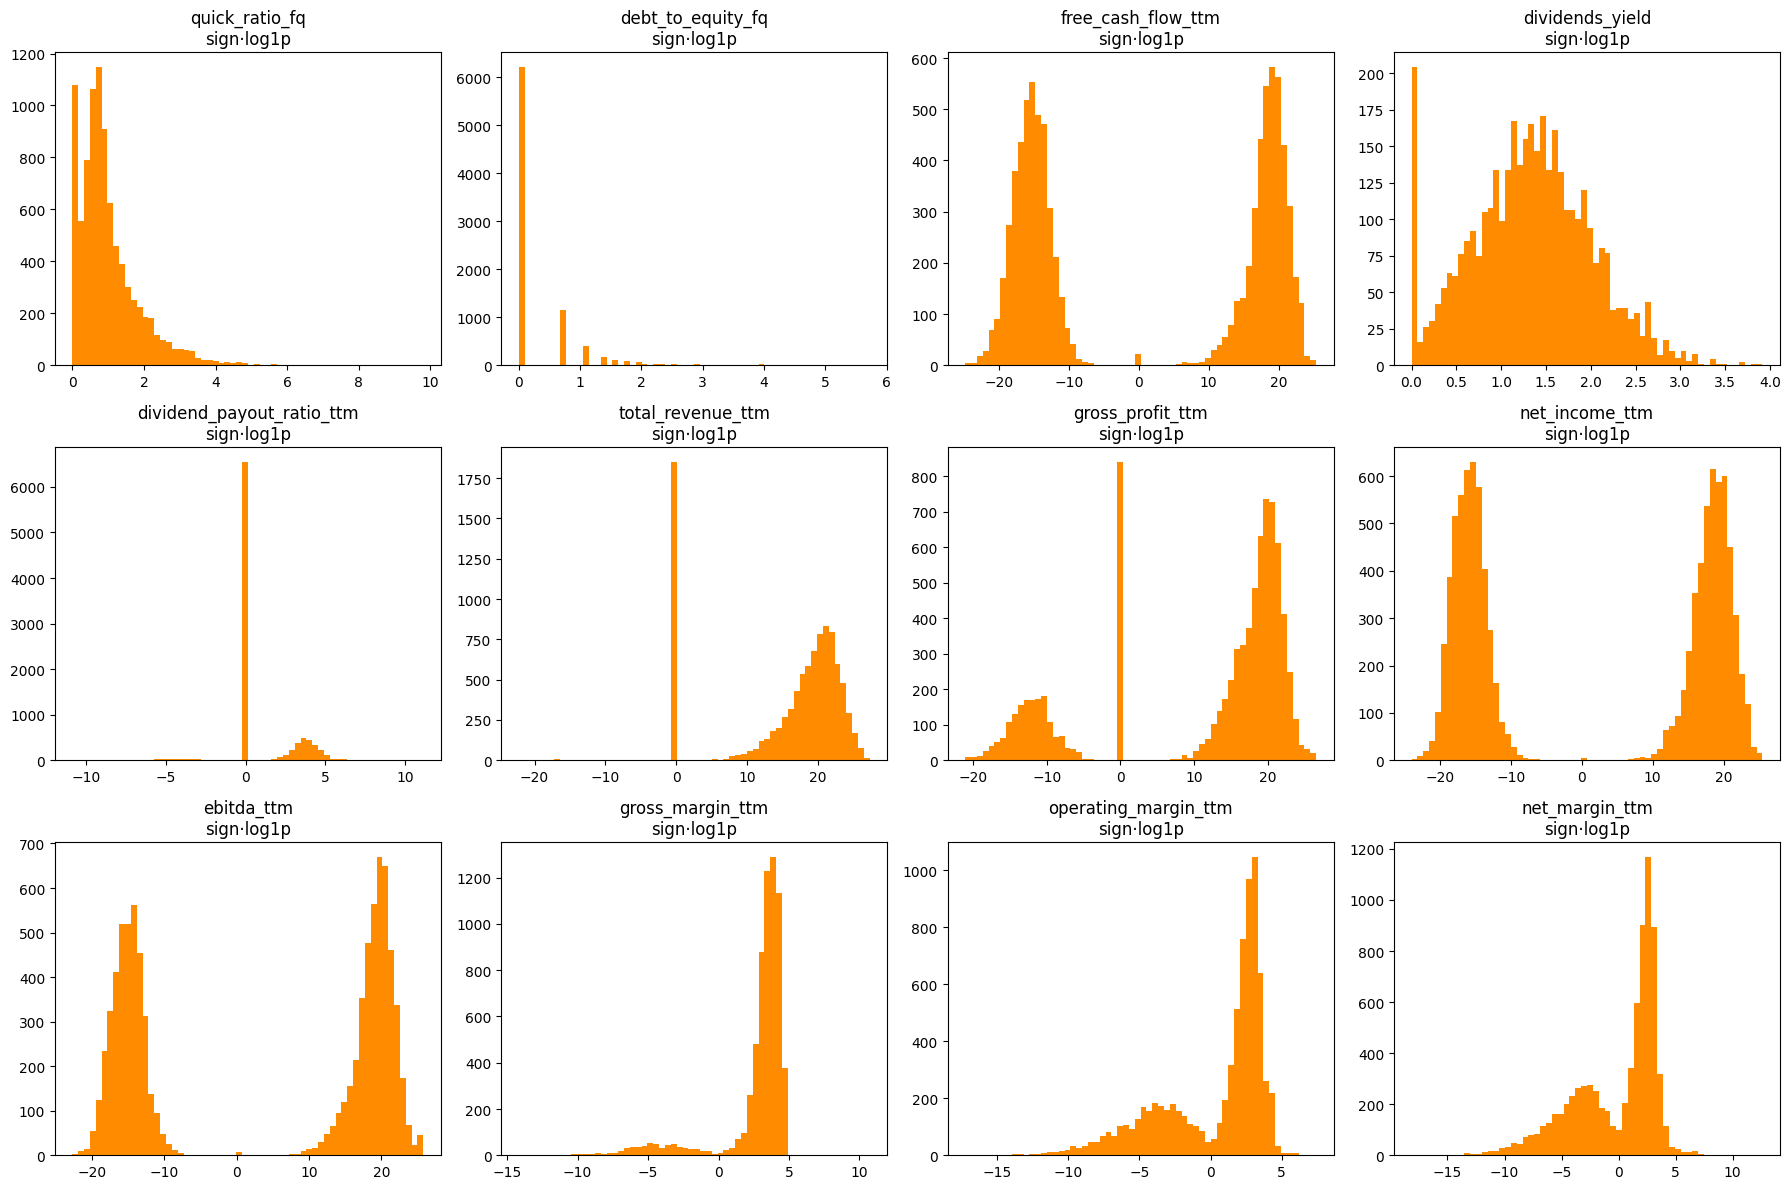

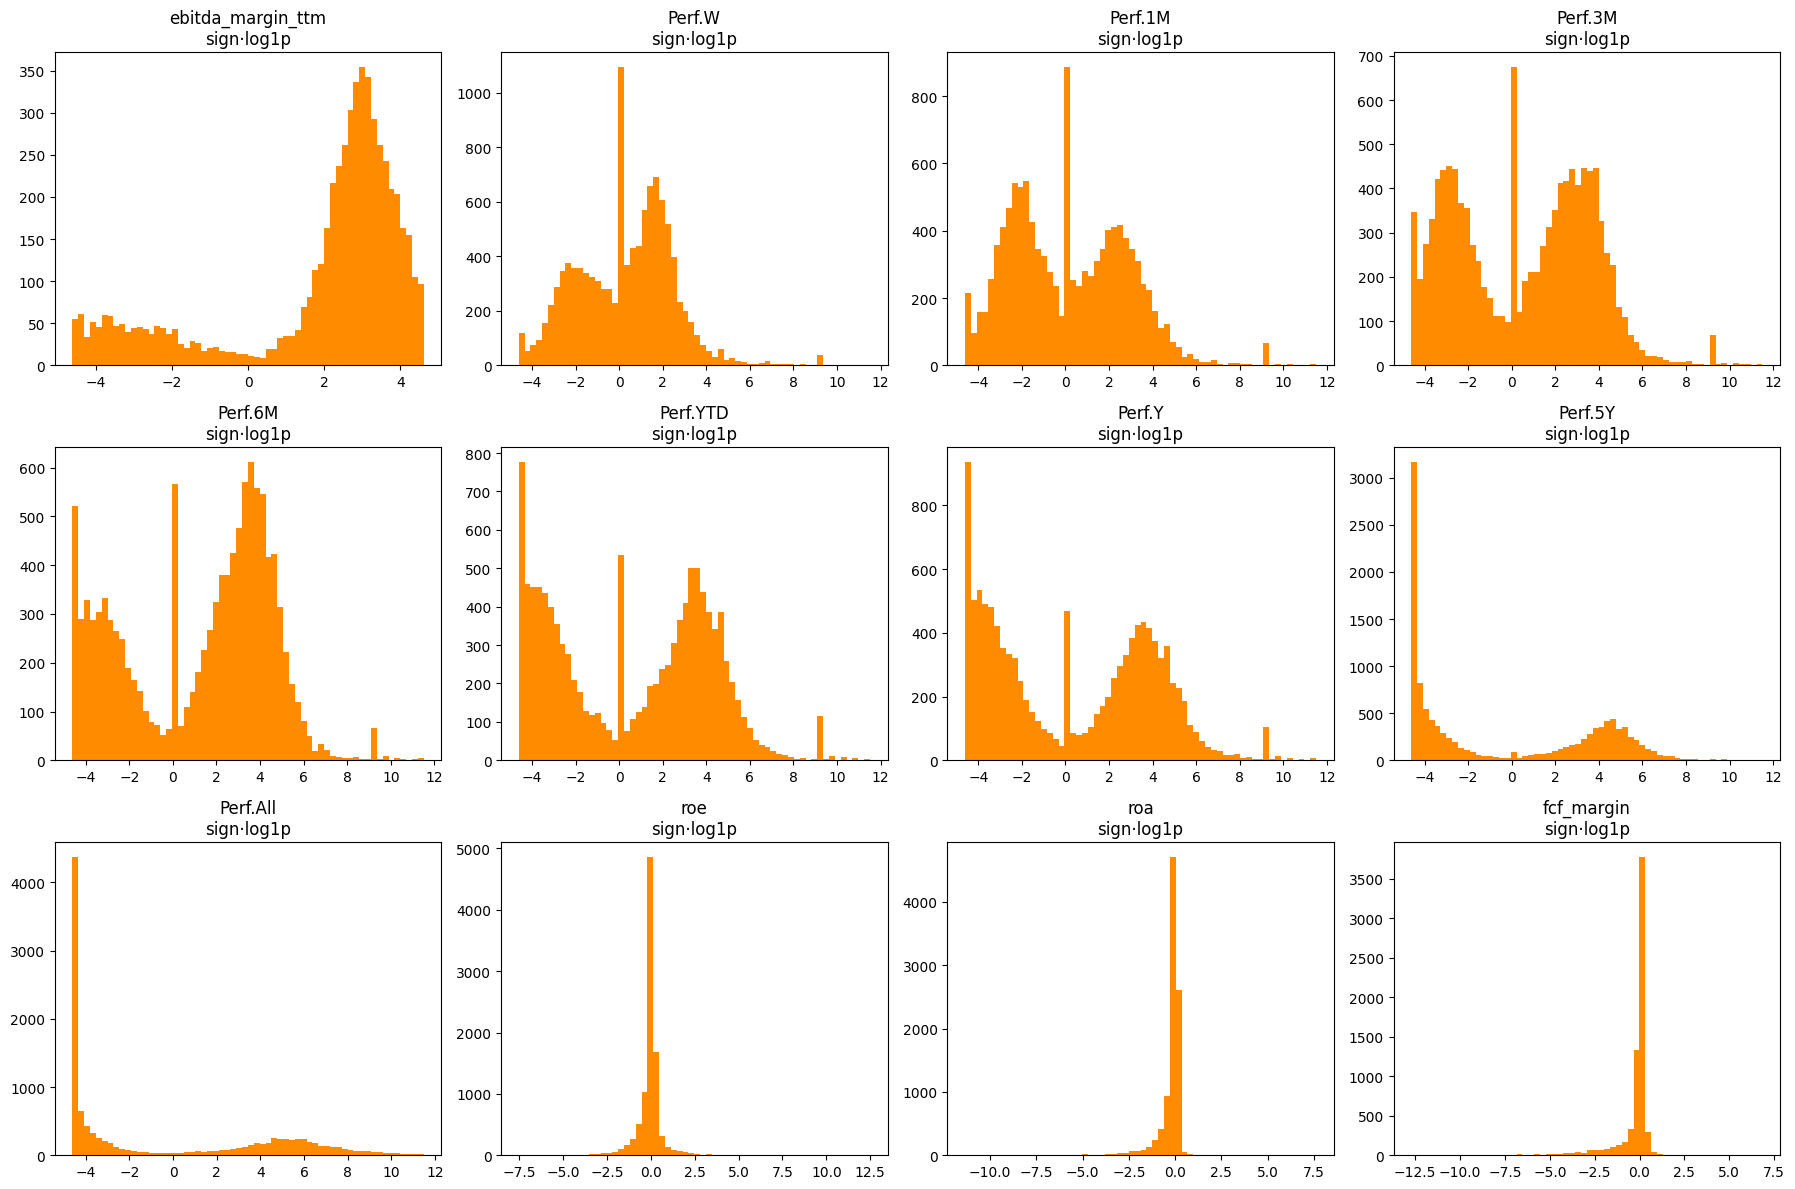

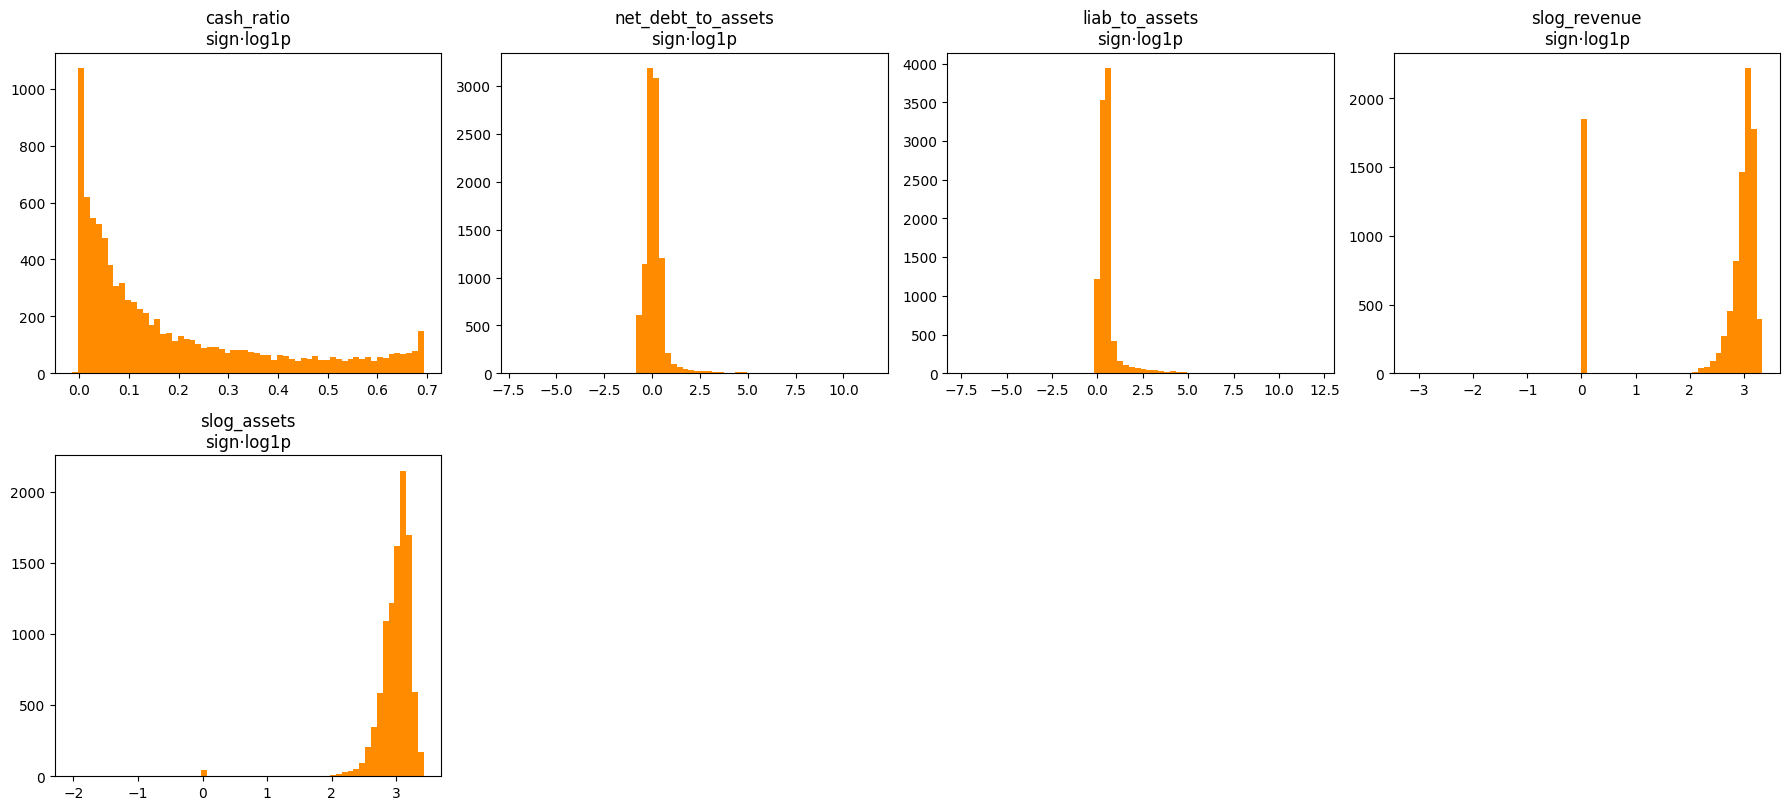

,skośność surowe,skośność po log
change,44.720,0.620
change_abs,35.930,1.500
volume,34.240,0.030
market_cap_basic,29.860,-0.900
price_earnings_ttm,44.580,1.020
total_assets_fq,10.750,-0.770
cash_n_short_term_invest_fq,25.410,-1.330
total_liabilities_fq,11.010,-0.220
total_debt_fq,15.110,-1.190
net_debt_fq,15.350,-0.340


In [208]:
plt.style.use("default")
NUM_ALL = list(NUM)

# najpierw wartości surowe, po 12 kolumn na rysunek
for start in range(0, len(NUM_ALL), 12):
    batch = NUM_ALL[start:start + 12]
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    for ax, c in zip(axes.ravel(), batch):
        ax.hist(df[c].dropna(), bins=60, color="steelblue")
        ax.set_title(f"{c}\nsurowe")
    for ax in axes.ravel()[len(batch):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

# potem po transformacji sign·log1p, ten sam podział
for start in range(0, len(NUM_ALL), 12):
    batch = NUM_ALL[start:start + 12]
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    for ax, c in zip(axes.ravel(), batch):
        ax.hist(slog(df[c].dropna()), bins=60, color="darkorange")
        ax.set_title(f"{c}\nsign·log1p")
    for ax in axes.ravel()[len(batch):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

skew_table = pd.DataFrame({
    "skośność surowe": [skew(df[c].dropna()) for c in NUM_ALL],
    "skośność po log": [skew(slog(df[c].dropna())) for c in NUM_ALL],
}, index=NUM_ALL)
display(skew_table.round(2))

**Wnioski z histogramów:**
- **Kwoty i ruch ceny, surowo:** `change`, `change_abs`, `volume`, `market_cap_basic`, `total_assets_fq`, `total_liabilities_fq`, `net_debt_fq`, `total_equity_fq`, `free_cash_flow_ttm`, `net_income_ttm`, `ebitda_ttm` mają jeden wysoki słupek przy zerze i oś rozciągniętą do ekstremów. Skośność wynosi od ok. 10 do ponad 40, więc kształtu nie widać.
- **Kwoty po logarytmie, dzwon z ogonem w lewo:** `market_cap_basic`, `total_assets_fq`, `total_liabilities_fq`, `total_equity_fq`, `total_debt_fq`, `net_debt_fq`, `volume`. Skośność po logarytmie jest ujemna albo bliska zera.
- **Kwoty po logarytmie, dwa garby:** `free_cash_flow_ttm`, `net_income_ttm`, `ebitda_ttm`. Jeden garb jest dodatni, drugi ujemny, a środek jest pusty. Rozdzielają się firmy na plusie i na minusie.
- **Kolumny z zerami:** `total_debt_fq`, `total_revenue_ttm`, `gross_profit_ttm`, `dividend_payout_ratio_ttm`, `debt_to_equity_fq` mają po logarytmie słupek dokładnie przy zerze. To spółki bez długu, bez przychodu, bez zysku brutto albo bez dywidendy.
- **Ruch ceny** (`change`, `change_abs`, `Perf.*`): surowo jeden słupek przy zerze. Po logarytmie skupienie przy zerze i przy lewym końcu (zwrot bliski -100%) oraz garby przy wzrostach.
- **Marże i zwroty** (`net_margin_ttm`, `operating_margin_ttm`, `gross_margin_ttm`, `ebitda_margin_ttm`, `roe`, `roa`, `fcf_margin`): surowo tylko słupek przy zerze. Po logarytmie marże mają pik przy ok. 3 (dobra rentowność) i ogon w lewo (straty). `roe` i `roa` mają wąski pik przy zerze z ogonami w obie strony.
- **Płynność** (`current_ratio_fq`, `quick_ratio_fq`, `cash_ratio`): po logarytmie pik przy małych wartościach i ogon w prawo. `current_ratio_fq` i `quick_ratio_fq` mają ten sam kształt (r = 1,00).
- **Zadłużenie** (`debt_to_equity_fq`, `net_debt_to_assets`, `liab_to_assets`): po logarytmie `debt_to_equity_fq` ma najwyższy słupek przy zerze i malejące słupki w prawo. `net_debt_to_assets` i `liab_to_assets` mają wąski pik przy zerze lub przy ok. 0,5 i ogony w obie strony.
- **Skala** (`slog_revenue`, `slog_assets`): są już logarytmami. `slog_assets` ma dzwon przy ok. 20–22, a `slog_revenue` dodatkowo słupek przy zerze.
- **Dywidenda** (`dividends_yield`): surowo skupienie przy 0–10%. Po logarytmie dzwon przy ok. 1–1,5.
- **Najbardziej wyróżniają się:** ruch ceny (`change`, `change_abs`, `Perf.*`), kolumny z zerami oraz kolumny z dwoma garbami (`net_income_ttm`, `ebitda_ttm`, `free_cash_flow_ttm`).

## 3. Decyzja o kolumnach

Każda z 45 kolumn dostaje decyzję: zostaje, odpada albo jest celem. Decyzja opiera się na zasadzie, znaczeniu kolumny i wykresach z sekcji 2.

### 3a. Co odrzucamy i dlaczego

Tabela zawiera jedną decyzję na kolumnę.

Powody odrzucenia są cztery:
- **Wyciek:** kolumna zawiera dane, z których da się wyliczyć P/E albo cenę. Model dostałby odpowiedź w cechach, więc taka kolumna odpada, nawet jeśli wykres wygląda dobrze.
- **Nie cecha firmy:** identyfikator, giełda, zbyt szczegółowa branża albo ruch kursu, który mówi o nastroju rynku, a nie o wynikach firmy.
- **Kwota użyta do wskaźnika:** surowa kwota (np. aktywa), z której już policzyliśmy wskaźnik (np. `roa`, czyli zysk do aktywów). Model dostaje wskaźnik, który da się porównywać między firmami dużymi i małymi, a surowa kwota mówi głównie o wielkości.
- **Braki (describe):** kolumna z ponad 40% braków odpada, bo jej brak wycina z regresji dużo spółek. Próg 40% leży w największej przerwie między cechami (33,8% → 42,1%). Dotyczy `gross_margin_ttm` (44,3%), `ebitda_margin_ttm` (51,9%) i `fcf_margin` (42,1%). Mediana z describe pokazuje typową wartość; średnia i odchylenie są rozdęte przez skrajne spółki, więc w decyzji ich nie używamy.

Kolumna „co widać na wykresach” pochodzi z box-plotów i histogramów z sekcji 2. Przy wycieku powodem jest wzór P/E, a wykres tylko pokazuje, jak kolumna wygląda.

| kolumna | decyzja | braki % | mediana | powód | co widać na wykresach |
|---|---|---|---|---|---|
| `ticker` | identyfikator | 0,0% | — | symbol spółki, potrzebny tylko do łączenia tabel | tekst, bez rozkładu do oceny |
| `sector` | zostaje jako kod | 0,1% | — | branża, jedna z 21 kategorii; zamieniamy na kod 1–20 w sekcji 4b | tekst, rozkład kategorii w sekcji 5 |
| `industry` | odrzucona | 0,1% | — | węższa branża, 130 kategorii; model z tyloma kodami byłby za duży na ten zbiór | tekst, sekcja 5 |
| `exchange` | odrzucona | 0,0% | — | giełda (NASDAQ, NYSE itd.) to miejsce notowania, a nie cecha firmy | tekst, najczęściej OTC (sekcja 5) |
| `change` | odrzucona | 0,2% | 0,23 | zmiana ceny z ostatniego dnia: ruch kursu, nie wynik firmy | box-plot: połowa spółek przy zerze, kropki ciągną się w obie strony do ekstremów; po logarytmie rozkład jest symetryczny wokół zera z ogonami, czyli to zmienność kursu |
| `change_abs` | odrzucona | 0,1% | 0,00 | ta sama zmiana ceny co `change`, tylko bez znaku | najwięcej kropek ze wszystkich kolumn (ok. 24%); surowo jeden słupek przy zerze, po logarytmie też skupienie przy zerze |
| `volume` | odrzucona | 0,0% | 15 232 | liczba akcji, które zmieniły właściciela w ciągu dnia: zainteresowanie kursem, nie wynik firmy | surowo jeden słupek przy zerze; po logarytmie dzwon z ogonem w lewo i prawie żadnych kropek. Wykres nie wskazuje na usunięcie, powodem jest to, że obrót nie mówi o wynikach firmy |
| `market_cap_basic` | odrzucona | 2,9% | 191,5 mln | kapitalizacja to cena razem z liczbą akcji; P/E to kapitalizacja podzielona przez zysk, więc kolumna zdradza odpowiedź (wyciek) | box-plot: pudełko w zakresie milionów do miliardów, kropki aż do bardzo dużych spółek; po logarytmie dzwon z ogonem w lewo, typowa firma ma kapitalizację rzędu setek milionów. Wykres jest czytelny, decyduje wyciek |
| `price_earnings_ttm` | target | 59,8% | 18 | to, co przewidujemy, więc nie jest cechą | box-plot: połowa spółek ma P/E od ok. 10 do 30, dolny wąs prawie przy zerze, kropki w górę do bardzo wysokich wartości; po logarytmie jeden garb przy 2,5–3 i ogon w prawo |
| `total_assets_fq` | odrzucona | 14,6% | 439,6 mln | aktywa ogółem; policzono z nich `roa` i `slog_assets`, więc model dostaje te wskaźniki | box-plot: kwoty w szerokim zakresie, kropki daleko w górę; po logarytmie dzwon przy 20–22 z ogonem w lewo i kilkoma spółkami przy zerze |
| `cash_n_short_term_invest_fq` | odrzucona | 22,9% | 31,0 mln | gotówka i krótkoterminowe lokaty; z niej policzono `cash_ratio` (udział gotówki w majątku), a model dostaje ten udział | box-plot: kwoty w szerokim zakresie; po logarytmie garb przy 17–19, słupek przy zerze i ogon w stronę ujemnych wartości (podejrzane wpisy) |
| `total_liabilities_fq` | odrzucona | 15,1% | 184,6 mln | zobowiązania ogółem; z nich policzono `liab_to_assets` (zobowiązania do majątku) | po logarytmie wyraźny dzwon przy 18–20 z niewielkim ogonem; prawie bez kropek. Odrzucona, bo model dostaje gotowy stosunek |
| `total_debt_fq` | odrzucona | 14,9% | 44,1 mln | dług ogółem; informacja o długu jest już w `debt_to_equity_fq` i `net_debt_to_assets` | po logarytmie szeroki rozkład od ok. 10 do 25 i osobny słupek przy zerze (ok. 1 200 spółek bez długu). Te zera są ważne, ale druga kolumna o długu jest zbędna |
| `net_debt_fq` | odrzucona | 15,1% | 2,1 mln | dług netto, czyli dług minus gotówka; z niej policzono `net_debt_to_assets` (dług netto do majątku) | box-plot: pudełko szerokie, wąs w dół do dużych ujemnych wartości (firmy, które mają więcej gotówki niż długu); po logarytmie dwa garby: przy ok. -15 (gotówka przewyższa dług) i przy ok. 20 (dług przewyższa gotówkę) |
| `total_equity_fq` | odrzucona | 14,7% | 154,2 mln | kapitał własny (to, co należy do właścicieli); z niego policzono `roe` | po logarytmie dwa skupienia: większość przy ok. 20 (dodatni kapitał), grupa przy ok. -15 (firmy z ujemnym kapitałem). Dlatego ma dużo kropek po logarytmie (ok. 15%). Odpada, bo informacja jest już w `roe` |
| `current_ratio_fq` | zostaje | 16,2% | 1,41 | wskaźnik płynności: majątek obrotowy do zobowiązań krótkoterminowych, czyli czy firma pokryje krótkie długi | box-plot: połowa spółek ma wartość od ok. 0,5 do 4, kropki sięgają wysoko; po logarytmie pik przy 0–1 i ogon w prawo. Ten sam kształt co `quick_ratio_fq` |
| `quick_ratio_fq` | zostaje | 24,1% | 1,19 | szybka płynność: jak wyżej, ale bez zapasów, bo zapasy trudno szybko zamienić na gotówkę | box-plot prawie taki sam jak dla `current_ratio_fq`; po logarytmie pik przy 0,5–1. Para z `current_ratio_fq` (r = 1,00) jest do decyzji w sekcji 6 |
| `debt_to_equity_fq` | zostaje | 27,6% | 0,00 | dług do kapitału własnego: ile długu przypada na złotówkę kapitału właścicieli | box-plot: mediana na zerze, czyli większość spółek nie ma długu albo ma go mało; kropki do wysokich wartości. Po logarytmie najwyższy słupek przy zerze, potem coraz mniej w prawo |
| `free_cash_flow_ttm` | odrzucona | 27,1% | -11 440 | wolne przepływy pieniężne w pieniądzach; w modelu jest ich udział w przychodach (`fcf_margin`) | box-plot: bardzo szerokie pudełko od ujemnych do dodatnich kwot, kropki w obie strony; po logarytmie dwa garby (firmy zarabiające gotówkę i ją wypalające) z pustym środkiem |
| `dividends_yield` | odrzucona | 66,9% | 2,79 | stopa dywidendy: roczna dywidenda do ceny akcji; payout podzielony przez tę stopę daje P/E (wyciek) | box-plot: pudełko 1–6%, mało kropek; po logarytmie dzwon przy 1–1,5. Wykres wygląda normalnie, odrzucamy ją przez wzór P/E |
| `dividend_payout_ratio_ttm` | zostaje | 19,2% | 0,00 | jaki procent zysku firma wypłaca akcjonariuszom jako dywidendę; to osobna decyzja firmy, nie sam wzór P/E | box-plot: mediana na zerze, bo wiele firm nie płaci dywidendy; kropki w obie strony, część powyżej 1000%. Po logarytmie duży słupek przy zerze (brak dywidendy) i grupa płacących przy 3–4 |
| `total_revenue_ttm` | odrzucona | 17,7% | 164,0 mln | przychody ogółem; z nich policzono `slog_revenue` (logarytm przychodów) | box-plot: pudełko w zakresie milionów do miliardów, pojedyncze ujemne przychody (podejrzane); po logarytmie słupek przy zerze (firmy bez przychodu), garb przy ok. 21 i ogon w lewo |
| `gross_profit_ttm` | odrzucona | 28,3% | 42,5 mln | zysk brutto w pieniądzach; w modelu jest jego marża (`gross_margin_ttm`), czyli ten sam wynik w relacji do przychodu | po logarytmie dwa garby (straty przy ok. -10, zyski przy ok. 20) i słupek przy zerze. Kwota zależy od wielkości firmy, marża już to uwzględnia |
| `net_income_ttm` | odrzucona | 17,7% | 127 483 | zysk netto w pieniądzach; z niego liczymy `roe` i `roa` | po logarytmie dwa garby: straty przy ok. -15, zyski przy ok. 18, przerwa przy zerze. Ten sam sygnał jest w `roe`, `roa` i marży netto, więc kwotę pomijamy |
| `ebitda_ttm` | odrzucona | 27,5% | 3,3 mln | zysk operacyjny przed amortyzacją i odsetkami w pieniądzach; jej marża (`ebitda_margin_ttm`) odpada w 3a przez braki powyżej 40% | po logarytmie dwa garby (ok. -15 i ok. 20). Jak przy zysku netto, różnice między firmami mierzy marża, a nie kwota |
| `gross_margin_ttm` | odrzucona | 44,3% | 33 | marża brutto: ile procent przychodu zostaje po kosztach bezpośrednich **Odpada po regule braków (powyżej 40%).** | box-plot: pudełko w zakresie ok. 20–70%, kropki poniżej zera (straty) i powyżej 100% (podejrzane). Po logarytmie wąski pik przy ok. 4 (typowa marża) i ogon w lewo, czyli firmy ze stratą brutto |
| `operating_margin_ttm` | zostaje | 33,8% | 7,37 | marża operacyjna: zysk z działalności podstawowej do przychodu | box-plot: pudełko od ok. -10 do 30%, kropki w obie strony; po logarytmie pik przy ok. 3 i długi ogon w lewo (straty). Silnie powiązana z marżą netto (r = -0,84) |
| `net_margin_ttm` | zostaje | 33,7% | 3,76 | marża netto: zysk netto do przychodu, czyli to, co zostaje po wszystkich kosztach | box-plot: pudełko od ok. -10 do 20%, kropki do bardzo dużych wartości; po logarytmie pik przy 2–3, ogon w lewo do strat. Ujemna korelacja z log(P/E) |
| `ebitda_margin_ttm` | odrzucona | 51,9% | 15 | marża EBITDA: zysk przed amortyzacją i odsetkami do przychodu **Odpada po regule braków (powyżej 40%).** | box-plot: pudełko 5–35%, wąs w dół do ok. -100%, kropki przy zerze i poniżej; po logarytmie garb przy 3 i długi ogon w lewo |
| `Perf.W` | odrzucona | 5,3% | 0,49 | zwrot ceny w ostatnim tygodniu: ruch kursu, nie wynik firmy | box-plot: pudełko przy zerze, kropki w obie strony do ±100 000%; po logarytmie dwa garby przy ok. ±2 i słupek przy zerze (kurs bez zmiany) |
| `Perf.1M` | odrzucona | 1,1% | 0,00 | zwrot ceny w ostatnim miesiącu: ruch kursu | po logarytmie dwa garby (spadki i wzrosty) przy ok. ±2 i skupienie przy lewym końcu (zwrot bliski -100%) |
| `Perf.3M` | odrzucona | 1,1% | 1,15 | zwrot w ostatnich 3 miesiącach: ruch kursu | box-plot: pudełko od ok. -10 do 20%; po logarytmie dwa garby: spadki przy ok. -3 i wzrosty przy ok. 3 |
| `Perf.6M` | odrzucona | 1,1% | 8,14 | zwrot w ostatnich 6 miesiącach: ruch kursu | box-plot: pudełko od ok. -10 do 50%; po logarytmie dwa garby i słupek przy zerze |
| `Perf.YTD` | odrzucona | 1,0% | 2,04 | zwrot od początku roku: ruch kursu | po logarytmie wiele spółek przy lewym końcu (zwrot bliski -100%) i garb dodatni przy ok. 3–4 |
| `Perf.Y` | odrzucona | 1,1% | 0,00 | zwrot w ostatnim roku: ruch kursu | po logarytmie duży słupek przy lewym końcu i rozproszony garb dodatni |
| `Perf.5Y` | odrzucona | 1,1% | -16 | zwrot w ostatnich 5 latach: ruch kursu | box-plot: pudełko od ok. -10 do 60%; po logarytmie najwięcej spółek przy lewym końcu, czyli grupa, która w 5 lat prawie straciła wartość |
| `Perf.All` | odrzucona | 1,2% | -33 | zwrot od pierwszego notowania: zależy od tego, kiedy spółka trafiła na giełdę, więc nie jest cechą firmy | wąs do ok. 300%, kropki do bardzo dużych wartości; po logarytmie szeroki rozrzut i skupienie przy lewym końcu |
| `roe` | zostaje | 18,1% | 0,05 | zwrot z kapitału własnego: ile zysku firma zarabia na pieniądzach właścicieli | box-plot: mediana przy zerze, kropki w obie strony (firmy z bardzo małym kapitałem mają skrajne ROE); po logarytmie wąski pik przy zerze z ogonami. Słaby związek z log(P/E) |
| `roa` | zostaje | 18,4% | 0,00 | zwrot z aktywów: zysk netto do majątku | box-plot: mediana przy zerze, kropki w obie strony; po logarytmie wąski pik przy zerze. Najmocniejszy pojedynczy związek z log(P/E) (ujemny) |
| `fcf_margin` | odrzucona | 42,1% | 0,04 | marża wolnych przepływów: gotówka po inwestycjach do przychodu **Odpada po regule braków (powyżej 40%).** | box-plot: mediana przy zerze, dużo kropek w obie strony; po logarytmie wąski pik przy zerze i ogon w lewo (firmy wypalające gotówkę) |
| `cash_ratio` | zostaje | 23,4% | 0,11 | udział gotówki w majątku: jaką część aktywów firma trzyma w gotówce | box-plot: pudełko 0–0,2, kropki do 1 (cała gotówka); po logarytmie pik przy zerze i stopniowy spadek w prawo. Silna ujemna korelacja z `net_debt_to_assets` (r = -0,82) |
| `net_debt_to_assets` | zostaje | 15,5% | 0,06 | dług netto do majątku: ile długu netto przypada na złotówkę aktywów | box-plot: mediana przy zerze, wąskie pudełko, kropki do wysokich wartości; po logarytmie wąski pik przy zerze i ogony w obie strony. Para z `cash_ratio` do decyzji w sekcji 6 |
| `liab_to_assets` | zostaje | 15,5% | 0,57 | zobowiązania do majątku: jaka część aktywów jest sfinansowana zobowiązaniami | box-plot: pudełko przy zerze do ok. 1, kropki do bardzo wysokich wartości; po logarytmie pik przy ok. 0,5 i ogon w prawo |
| `slog_revenue` | zostaje | 17,7% | 19 | logarytm przychodów: wielkość firmy na skali, na której różnice są proporcjonalne | box-plot: pudełko wysoko, przy 20–24; kropki przy zerze i poniżej (firmy bez przychodu lub z błędem). Już po logarytmie, więc drugiego nie robimy |
| `slog_assets` | zostaje | 14,6% | 20 | logarytm aktywów: wielkość firmy w majątku | box-plot: wąskie pudełko przy ok. 20, kilka kropek w dół; silny związek z `slog_revenue` (r = 0,91), więc jedna z tych dwóch kolumn wystarczy |

### 3b. Wybór cech i usunięcie kolumn

Z 45 kolumn zostaje 16: `ticker`, target, `sector` i 13 cech liczbowych. Pozostałe 29 kolumn odpada.

Target to `price_earnings_ttm`. Cechy liczbowe to wskaźniki fundamentalne, które nie zawierają ceny:
- bez `market_cap_basic`, bo P/E = kapitalizacja / zysk, więc kapitalizacja zdradzałaby target,
- bez `dividends_yield`, bo razem z payoutem daje P/E,
- bez `Perf.*` i `change`, bo to ruch ceny.
- bez `gross_margin_ttm`, `ebitda_margin_ttm` i `fcf_margin`, bo mają ponad 40% braków (reguła z 3a).

Kategorie: `sector` jest jakościowa, więc wchodzi do modelu dopiero w sekcji 4, jako kod na zbiorze regresji. `exchange` pomijamy, bo giełda nie jest cechą firmy, tylko miejscem notowania. `industry` pomijamy, bo ma 130 kategorii.

Po tym kroku `df` ma tylko `ticker`, target, `sector` i 13 cech. Pełna kopia z wszystkimi kolumnami zostaje w `df_all` i z niej korzystamy w sekcji 5.

In [209]:
# cechy regresji P/E: wskaźniki fundamentalne bez kapitalizacji, yielda i ruchu ceny
FEAT = [
    "net_margin_ttm", "roe", "roa", "dividend_payout_ratio_ttm",
    "operating_margin_ttm", "debt_to_equity_fq", "current_ratio_fq",
    "quick_ratio_fq", "cash_ratio", "net_debt_to_assets", "liab_to_assets",
    "slog_revenue", "slog_assets",
]
KEEP = ["ticker", TARGET, "sector"] + FEAT
# kopia przed usunięciem, do sekcji 5
df_all = df.copy()
REMOVED = [c for c in df_all.columns if c not in KEEP]
df = df[KEEP]
STAGES.append(("po wyborze cech", *df.shape))
print("Kolumn przed wyborem:", df_all.shape[1], "| po wyborze:", df.shape[1], "| usunięte:", len(REMOVED))
print("Liczba cech liczbowych:", len(FEAT), "| target:", TARGET)
print("Usunięte kolumny:", REMOVED)

Kolumn przed wyborem: 45 | po wyborze: 16 | usunięte: 29
Liczba cech liczbowych: 13 | target: price_earnings_ttm
Usunięte kolumny: ['change', 'change_abs', 'volume', 'market_cap_basic', 'industry', 'total_assets_fq', 'cash_n_short_term_invest_fq', 'total_liabilities_fq', 'total_debt_fq', 'net_debt_fq', 'total_equity_fq', 'free_cash_flow_ttm', 'dividends_yield', 'total_revenue_ttm', 'gross_profit_ttm', 'net_income_ttm', 'ebitda_ttm', 'gross_margin_ttm', 'ebitda_margin_ttm', 'Perf.W', 'Perf.1M', 'Perf.3M', 'Perf.6M', 'Perf.YTD', 'Perf.Y', 'Perf.5Y', 'Perf.All', 'exchange', 'fcf_margin']


Ta komórka sprawdza regułę z 3a na wybranych cechach. Tabela pokazuje braki i medianę dla wszystkich 45 kolumn (mediana tylko dla liczb).

Powyżej 40% braków są `price_earnings_ttm` (target), `dividends_yield` (już odrzucony), `gross_margin_ttm`, `ebitda_margin_ttm` i `fcf_margin`. Wśród cech, które zostają, najwyższe braki mają `operating_margin_ttm` (33,8%) i `net_margin_ttm` (33,7%), więc żadna nie przekracza progu.

In [210]:
# braki i mediana dla wszystkich 45 kolumn (mediana tylko dla liczb)
num_cols = df_all.select_dtypes("number").columns
stats_tab = pd.DataFrame({"braki %": (df_all.isna().mean() * 100).round(1)})
stats_tab["mediana"] = df_all[num_cols].median().reindex(df_all.columns)
# reguła: cecha z ponad 40% braków odpada
MISSING_LIMIT = 40
display(stats_tab.sort_values("braki %", ascending=False))
print(f"Kolumny z ponad {MISSING_LIMIT}% braków:", stats_tab.index[stats_tab["braki %"] > MISSING_LIMIT].tolist())
assert (stats_tab.loc[FEAT, "braki %"] <= MISSING_LIMIT).all()

,braki %,mediana
dividends_yield,66.900,2.795
price_earnings_ttm,59.800,17.886
ebitda_margin_ttm,51.900,14.535
gross_margin_ttm,44.300,33.005
fcf_margin,42.100,0.041
operating_margin_ttm,33.800,7.370
net_margin_ttm,33.700,3.760
gross_profit_ttm,28.300,"42,480,549.500"
debt_to_equity_fq,27.600,0.000
ebitda_ttm,27.500,"3,349,061.990"


Kolumny z ponad 40% braków: ['price_earnings_ttm', 'dividends_yield', 'gross_margin_ttm', 'ebitda_margin_ttm', 'fcf_margin']


## 4. Podział na zbiory

W tej sekcji regresja dostaje tylko spółki z P/E i kompletem cech. Target zamieniamy na logarytm, a zbiór dzielimy na trening, walidację i test.

### 4a. Odrzucenie braków

Wiersz odpada, gdy brakuje targetu albo którejkolwiek cechy.

Do regresji bierzemy spółki z P/E i kompletem cech.
- Odpada 6 978 spółek bez P/E.
- Odpada 1 295 spółek z P/E, ale z brakiem co najmniej jednej cechy.
- Zostaje 3 402 spółek.

Braków nie uzupełniamy, więc wiersz z brakiem cechy wypada w całości. Tabela pod kodem pokazuje, która cecha najczęściej wycina wiersz: `quick_ratio_fq` (962 spółek z P/E), `cash_ratio` (889), `debt_to_equity_fq` (241) i `operating_margin_ttm` (181).

In [211]:
no_target = df[TARGET].isna()
no_feat = df[TARGET].notna() & df[FEAT].isna().any(axis=1)
print(f"Wszystkie spółki po połączeniu: {len(df)}")
print(f"Odrzucono {int(no_target.sum())} spółek bez P/E")
print(f"Odrzucono {int(no_feat.sum())} spółek z P/E, ale z brakiem co najmniej jednej cechy")
df_reg = df.dropna(subset=[TARGET] + FEAT)
print(f"Zostaje {len(df_reg)} spółek do regresji P/E")
# które cechy najczęściej wycinają wiersz wśród spółek z P/E
miss_feat = df.loc[df[TARGET].notna(), FEAT].isna().sum()
display(miss_feat[miss_feat > 0].sort_values(ascending=False).to_frame("braki wśród spółek z P/E"))

Wszystkie spółki po połączeniu: 11675
Odrzucono 6978 spółek bez P/E
Odrzucono 1295 spółek z P/E, ale z brakiem co najmniej jednej cechy
Zostaje 3402 spółek do regresji P/E


,braki wśród spółek z P/E
quick_ratio_fq,962
cash_ratio,889
debt_to_equity_fq,241
operating_margin_ttm,181
net_margin_ttm,180
current_ratio_fq,144
liab_to_assets,79
net_debt_to_assets,77
roa,36
roe,35


### 4b. Logarytm targetu i podział train / valid / test

Target zamieniamy na logarytm, a zbiór regresji dzielimy na trzy części: trening, walidację i test.

- **P/E** to cena akcji podzielona przez zysk na akcję z ostatnich 12 miesięcy. P/E = 20 oznacza, że płacimy 20 zł za każdą złotówkę rocznego zysku.
- **Skośność P/E** wynosi 44,6: większość spółek ma P/E w okolicy 10–30, kilka ma tysiące. Model regresji minimalizuje błąd kwadratowy, więc jedna spółka z P/E 74 000 mogłaby sama dominować dopasowanie.
- **Logarytm** zmniejsza skośność do 1,0 i wyrównuje skalę: przejście z P/E 10 na 20 odpowiada przejściu z 100 na 200.
- **Predykcja:** model przewiduje log(P/E), a wynik zamieniamy z powrotem przez `exp()`. Błąd 0,3 w logarytmie to ok. 35% różnicy w P/E, niezależnie od wielkości P/E.
- **Dodatniość:** logarytm wymaga dodatnich wartości. W danych nie ma ujemnych P/E (sekcja 2b).
- **Skrajnie małe P/E:** najmniejsze wynosi ok. 0,00007 (log ok. -9,6). Prawdopodobnie to błąd jednostek lub danych. Tego nie sprawdzaliśmy.

In [212]:
# sector zamieniamy na jedną kolumnę z kodami (zmienna nieciągła), bez one-hot
print("Braki sektora w zbiorze regresji:", int(df_reg["sector"].isna().sum()))
df_reg = df_reg.dropna(subset=["sector"]).copy()
df_reg["sector"] = df_reg["sector"].astype("category")
SECTOR_MAP = pd.Series(df_reg["sector"].cat.categories, index=range(1, len(df_reg["sector"].cat.categories) + 1), name="sektor")
df_reg["sector"] = df_reg["sector"].cat.codes + 1
FEAT_ALL = FEAT + ["sector"]
print("Cechy regresji (liczbowe + kod sektora):", len(FEAT_ALL))
display(SECTOR_MAP.to_frame())

assert (df_reg[TARGET] > 0).all(), "P/E musi być dodatnie, żeby go zlogarytmować"
df_reg = df_reg.assign(log_pe=np.log(df_reg[TARGET]))

def split_data(data):
    # 70% trening, 15% walidacja, 15% test
    train, rest = train_test_split(data, test_size=0.30, random_state=42)
    valid, test = train_test_split(rest, test_size=0.50, random_state=42)
    return train, valid, test

reg_train, reg_valid, reg_test = split_data(df_reg)
print("Regresja P/E trening / walidacja / test:", len(reg_train), len(reg_valid), len(reg_test))
print("log(P/E) na treningu: średnia", round(reg_train["log_pe"].mean(), 3), "| odchylenie", round(reg_train["log_pe"].std(), 3))

Braki sektora w zbiorze regresji: 0
Cechy regresji (liczbowe + kod sektora): 14


,sektor
1,Commercial Services
2,Communications
3,Consumer Durables
4,Consumer Non-Durables
5,Consumer Services
6,Distribution Services
7,Electronic Technology
8,Energy Minerals
9,Finance
10,Health Services


Regresja P/E trening / walidacja / test: 2381 510 511
log(P/E) na treningu: średnia 3.081 | odchylenie 1.198


**Wnioski z podziału:**
- Z 11 675 spółek do regresji zostaje 3 402. Odrzucono 6 978 bez P/E i 1 295 z P/E, ale z brakiem co najmniej jednej cechy.
- Podział 70 / 15 / 15 daje 2 381 / 510 / 511 spółek. Na treningu log(P/E) ma średnią 3,081 i odchylenie 1,198.
- Podział nie jest stratyfikowany, bo target jest ciągły.

## 5. Dane kategoryczne i czasowe

Ta sekcja opisuje kolumny tekstowe (`sector`, `industry`, `exchange`) i sprawdza, czy w danych są kolumny czasowe.

In [213]:
CAT = ["sector", "industry", "exchange"]
for c in CAT:
    print(f"{c}: {df_all[c].nunique()} kategorii, braków: {int(df_all[c].isna().sum())}")
display(df_all["sector"].value_counts(dropna=False).to_frame("n"))
display(df_all["exchange"].value_counts().to_frame("n"))
print("Najczęstsze industry:")
display(df_all["industry"].value_counts().head(8).to_frame("n"))
print("Kolumny z datami lub czasem:", [c for c in df_all.columns if any(s in c.lower() for s in ["date", "time", "year", "quarter"])])

sector: 21 kategorii, braków: 6
industry: 130 kategorii, braków: 6
exchange: 5 kategorii, braków: 0


,n
sector,
Finance,2302
Non-Energy Minerals,1523
Health Technology,1397
Technology Services,1078
Electronic Technology,598
Producer Manufacturing,588
Commercial Services,520
Process Industries,442
Consumer Services,406


,n
exchange,
OTC,6126
NASDAQ,3278
NYSE,2027
AMEX,243
CBOE,1


Najczęstsze industry:


,n
industry,
Precious Metals,814
Packaged Software,651
Other Metals/Minerals,595
Regional Banks,510
Pharmaceuticals: Major,505
Biotechnology,400
Financial Conglomerates,376
Miscellaneous Commercial Services,372


Kolumny z datami lub czasem: []


**Wnioski z danych kategorycznych:**
- `sector`: 21 kategorii i 6 braków. Największa to `Finance` (2 302 spółki). Zamieniamy na kody 1–20 w sekcji 4, wchodzi do cech regresji.
- Braki sektora to NaN, czyli spółki bez sektora. Wszystkie 6 odpada już przy braku P/E lub cech, więc w zbiorze regresji NaN w sektorze nie ma.
- `industry`: 130 kategorii, największa `Precious Metals` (814). Za dużo na ten zbiór, więc pomijamy ją.
- `exchange`: 5 wartości, OTC to 6 126 spółek (52,5%). Nie wchodzi do cech, bo giełda nie jest cechą firmy.
- Nie ma kolumn z datami ani czasem, więc timestampów nie ma do obróbki.

## 6. Macierze korelacji

Mapa pokazuje korelację (r) między każdą parą cech regresji i log(P/E) w zbiorze treningowym. r przyjmuje wartości od -1 do +1.


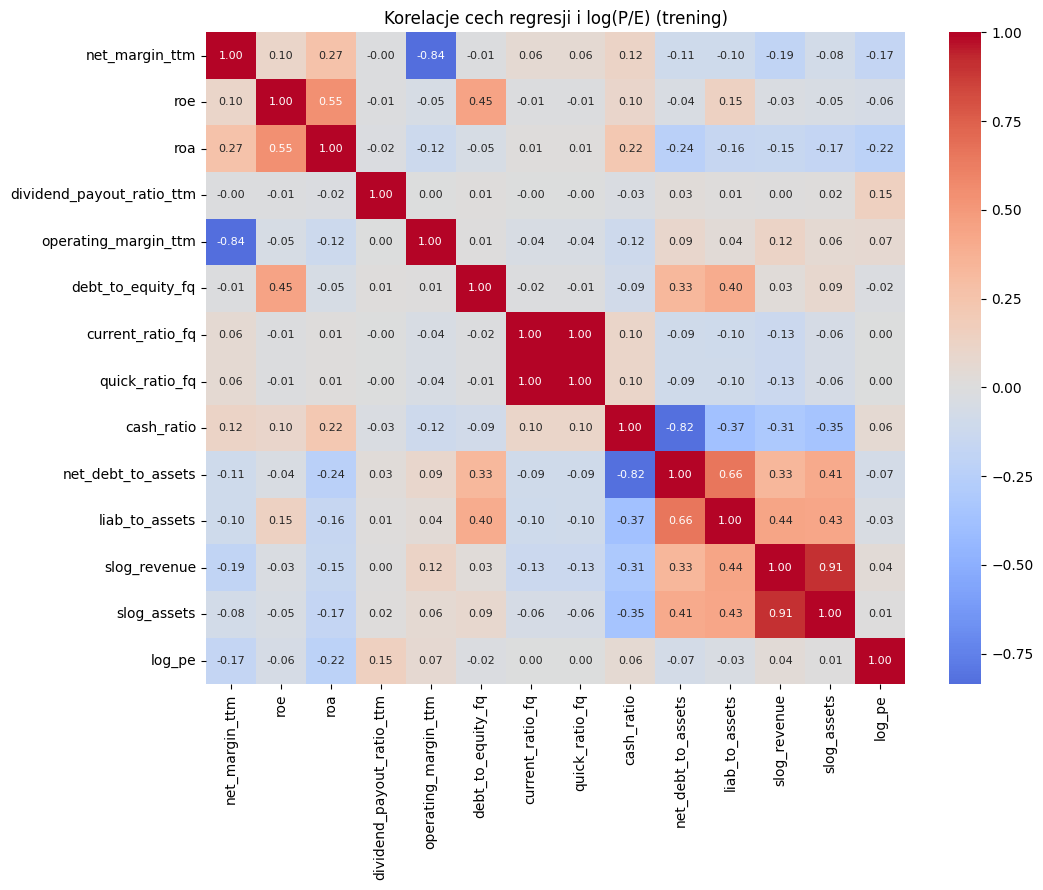

Pary cech z |r| > 0,7 (współliniowość):


,,r
current_ratio_fq,quick_ratio_fq,1.000
slog_revenue,slog_assets,0.910
net_margin_ttm,operating_margin_ttm,-0.840
cash_ratio,net_debt_to_assets,-0.820


Korelacja cech z log(P/E) (trening):


,korelacja
roa,-0.225
net_margin_ttm,-0.172
net_debt_to_assets,-0.072
roe,-0.059
liab_to_assets,-0.033
debt_to_equity_fq,-0.020
quick_ratio_fq,0.001
current_ratio_fq,0.001
slog_assets,0.005
slog_revenue,0.037


In [214]:
plt.figure(figsize=(11, 9))
sns.heatmap(reg_train[FEAT + ["log_pe"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Korelacje cech regresji i log(P/E) (trening)")
plt.tight_layout()
plt.show()

corr = reg_train[FEAT].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.7]
print("Pary cech z |r| > 0,7 (współliniowość):")
display(strong.sort_values(key=lambda s: s.abs(), ascending=False).round(2).to_frame("r"))

corr_logpe = reg_train[FEAT].corrwith(reg_train["log_pe"]).sort_values()
print("Korelacja cech z log(P/E) (trening):")
display(corr_logpe.to_frame("korelacja").round(3))

**Wnioski z mapy korelacji:**

**Pary współliniowe (|r| > 0,7):**
- `current_ratio_fq` i `quick_ratio_fq` (r = 1,00): na treningu prawie identyczne.
- `slog_revenue` i `slog_assets` (r = 0,91).
- `net_margin_ttm` i `operating_margin_ttm` (r = -0,84).
- `cash_ratio` i `net_debt_to_assets` (r = -0,82).

W każdej parze jedna cecha niesie prawie tę samą informację. Która zostaje w modelu, to decyzja otwarta.

**Umiarkowana korelacja (0,2–0,7):**
- **Zadłużenie:** `net_debt_to_assets` z `liab_to_assets` (0,66), `debt_to_equity_fq` z `liab_to_assets` (0,40) i z `net_debt_to_assets` (0,33).
- **Zwrot:** `roe` z `roa` (0,55), `roe` z `debt_to_equity_fq` (0,45), `net_margin_ttm` z `roa` (0,27).
- **Skala i zadłużenie:** `liab_to_assets` z `slog_revenue` (0,44) i z `slog_assets` (0,43), `net_debt_to_assets` z `slog_assets` (0,41) i z `slog_revenue` (0,33).
- **Gotówka:** `cash_ratio` z `liab_to_assets` (-0,37), z `slog_assets` (-0,35) i z `slog_revenue` (-0,31), oraz z `roa` (0,22).
- `roa` z `net_debt_to_assets` (-0,24).

**Związek z log(P/E)** (ostatni wiersz):
- `roa` (-0,22) ma najmocniejszy pojedynczy związek.
- `net_margin_ttm` (-0,17).
- `dividend_payout_ratio_ttm` (+0,15).
- Pozostałe cechy mają |r| poniżej 0,08.
- Sektor nie jest na mapie, bo jego kody 1–20 nie mają liczbowego sensu.

Żadna cecha nie ma |r| większego niż 0,25 z log(P/E).

## 7. Pairploty

Pairploty pokazują wykresy rozrzutu par cech w pięciu grupach tematycznych. Każda grupa kończy się kolumną `log_pe`, żeby widać było związek z celem.

Cechy dzielimy na grupy, bo wszystkie 13 cech naraz dałoby prawie 200 małych wykresów. Rysujemy 800 losowych spółek z treningu (stały seed).

- Każdy punkt to jedna spółka.
- Na przekątnej jest histogram zmiennej.
- Pasy przy zerze oznaczają wartości wyzerowane.
- Pojedyncze punkty daleko od chmury to wartości odstające.

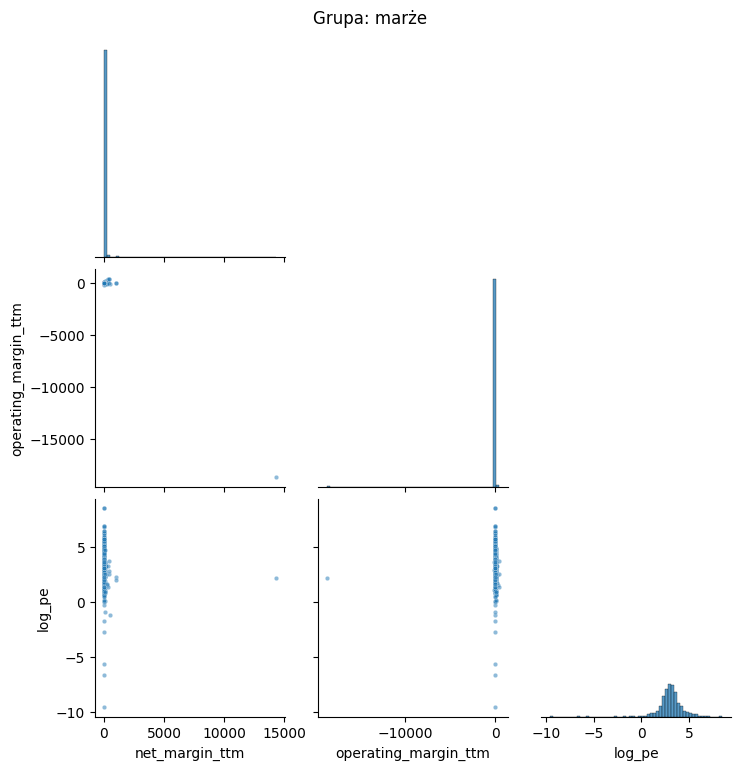

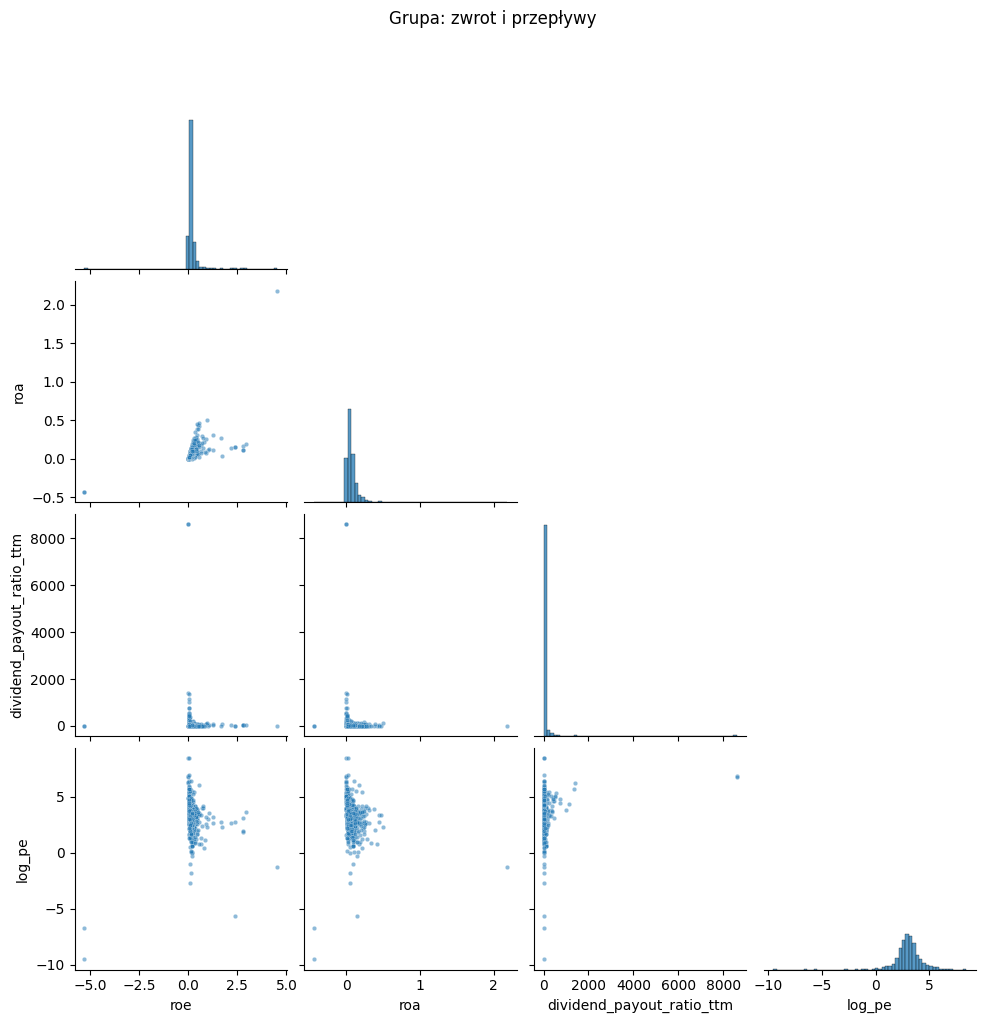

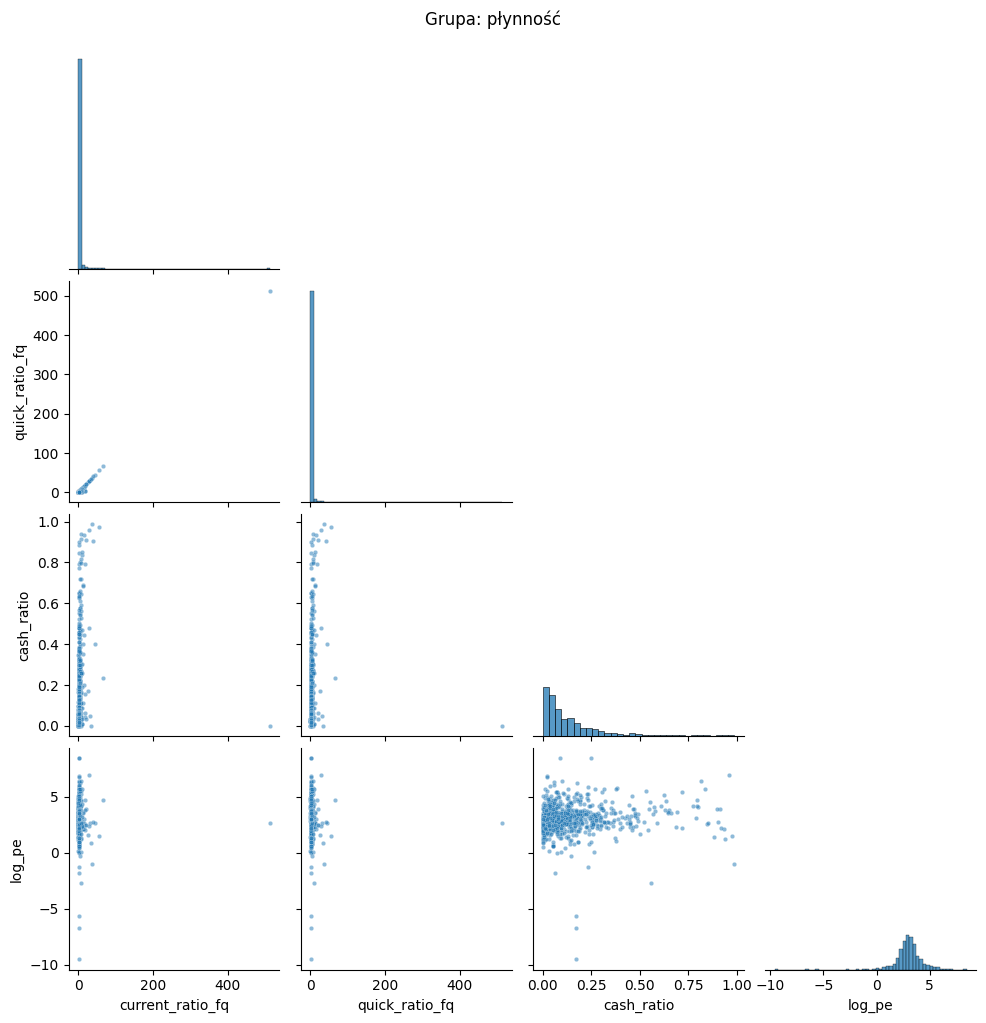

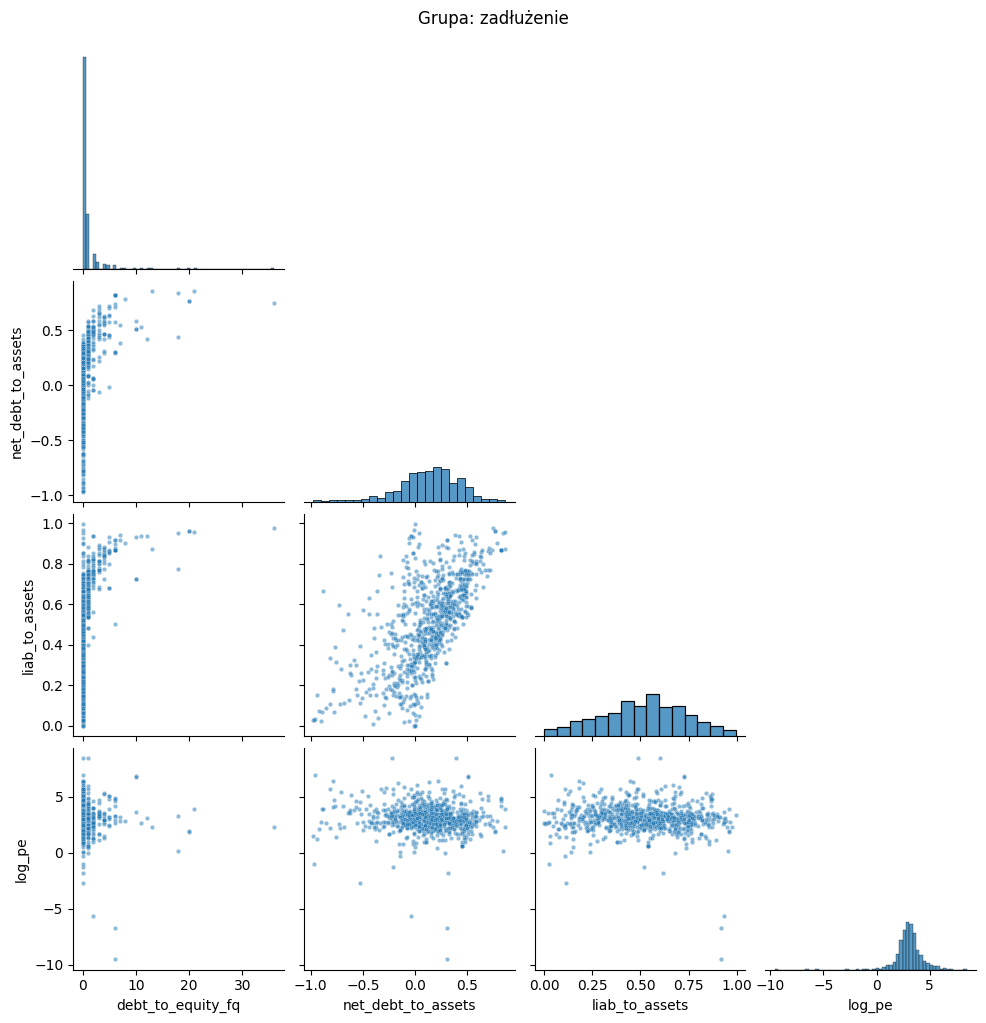

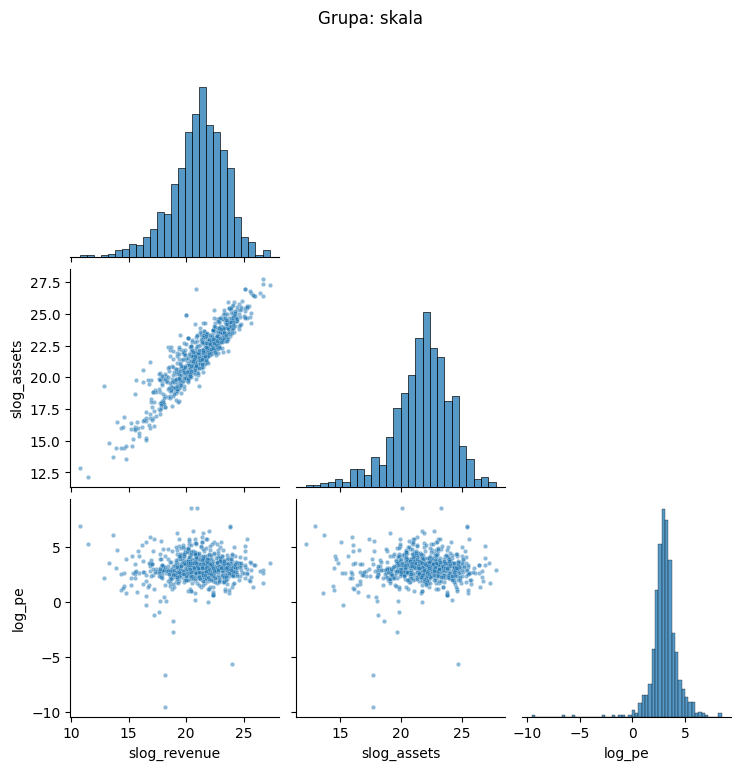

In [215]:
PAIR_GROUPS = {
    "marże": ["net_margin_ttm", "operating_margin_ttm"],
    "zwrot i przepływy": ["roe", "roa", "dividend_payout_ratio_ttm"],
    "płynność": ["current_ratio_fq", "quick_ratio_fq", "cash_ratio"],
    "zadłużenie": ["debt_to_equity_fq", "net_debt_to_assets", "liab_to_assets"],
    "skala": ["slog_revenue", "slog_assets"],
}
# losowa próbka 800 spółek z treningu, żeby punkty się nie zlewały
sample_df = reg_train.sample(800, random_state=42)
for name, cols in PAIR_GROUPS.items():
    g = sns.pairplot(sample_df[cols + ["log_pe"]], corner=True, plot_kws={"s": 10, "alpha": 0.5}, diag_kind="hist")
    g.figure.suptitle(f"Grupa: {name}", y=1.02)
    plt.show()

**Wnioski z pairplotów:**

**Marże** (`net_margin_ttm`, `operating_margin_ttm`): większość spółek leży przy zerze, a oś rozciągają pojedyncze skrajne punkty (zysk netto do ok. 14 000%, marża operacyjna do ok. -18 000%). Wewnątrz chmury widać ujemną zależność (r = -0,84), ale w pasie z log(P/E) nie ma kierunku.

**Zwrot i przepływy** (`roe`, `roa`, `dividend_payout_ratio_ttm`): `roe` i `roa` tworzą wiązkę z dodatnim kierunkiem (r = 0,55), z kilkoma skrajnymi punktami (roe ok. -5, roa ok. 2). `dividend_payout_ratio_ttm` ma pionowy pas przy zerze (firmy bez dywidendy) i kilka punktów powyżej 1 000%. Z log(P/E) chmury są szerokie, a `roa` ma najmocniejszy związek (r = -0,22).

**Płynność** (`current_ratio_fq`, `quick_ratio_fq`, `cash_ratio`): `current_ratio_fq` i `quick_ratio_fq` leżą na jednej linii (r = 1,00), a jedna spółka ma wartość ok. 500. `cash_ratio` ma histogram skupiony przy zerze z ogonem do 1. Z log(P/E) chmury są płaskie.

**Zadłużenie** (`debt_to_equity_fq`, `net_debt_to_assets`, `liab_to_assets`): `debt_to_equity_fq` ma większość wartości przy zerze, a nieliczne spółki sięgają 10–35. `net_debt_to_assets` i `liab_to_assets` tworzą rosnącą chmurę (r = 0,66). Spółki z log(P/E) poniżej -5 mają zwykle `liab_to_assets` ok. 0,9 i więcej.

**Skala** (`slog_revenue`, `slog_assets`): prawie liniowa zależność (r = 0,91), a histogramy są dzwonowe z lewym ogonem. Z log(P/E) chmura jest płaska, a punkty poniżej -5 leżą przy `slog_assets` ok. 17–18.

Pojedyncze spółki z log(P/E) poniżej -5 (P/E bliskie zera) widać jako pionowe pasy w kilku grupach.

## 8. Podsumowanie zbiorów

Tabela pokazuje liczbę wierszy i kolumn na każdym etapie. Pod nią jest podsumowanie wyników EDA dla modelu.

In [216]:
STAGES.append(("regresja P/E (kompletne wiersze)", len(df_reg), df_reg.shape[1]))
STAGES.append(("trening", len(reg_train), reg_train.shape[1]))
STAGES.append(("walidacja", len(reg_valid), reg_valid.shape[1]))
STAGES.append(("test", len(reg_test), reg_test.shape[1]))
summary = pd.DataFrame(STAGES, columns=["etap", "wiersze", "kolumny"]).set_index("etap")
display(summary)

print("Cechy w modelu:", len(FEAT_ALL), "| liczbowe:", len(FEAT), "| kod sektora: 1")
print("Kształt zbioru regresji (wiersze, kolumny):", df_reg.shape)
display(df_reg.head())

,wiersze,kolumny
etap,,
plik bazowy tradingview_all_stocks,11806,10
po połączeniu plików,14249,36
po usunięciu powtórek,11675,36
po wskaźnikach pochodnych,11675,45
po wyborze cech,11675,16
regresja P/E (kompletne wiersze),3402,17
trening,2381,17
walidacja,510,17
test,511,17


Cechy w modelu: 14 | liczbowe: 13 | kod sektora: 1
Kształt zbioru regresji (wiersze, kolumny): (3402, 17)


,ticker,price_earnings_ttm,sector,net_margin_ttm,roe,roa,dividend_payout_ratio_ttm,operating_margin_ttm,debt_to_equity_fq,current_ratio_fq,quick_ratio_fq,cash_ratio,net_debt_to_assets,liab_to_assets,slog_revenue,slog_assets,log_pe
0,NASDAQ:NVDA,52.716,7,52.410,0.865,0.615,1.138,58.090,0.000,4.214,3.597,0.404,-0.328,0.289,25.831,25.670,3.965
1,NASDAQ:AAPL,40.044,7,24.300,1.508,0.299,15.354,31.870,1.000,0.868,0.826,0.167,0.140,0.801,26.736,26.527,3.690
2,NASDAQ:MSFT,38.325,18,36.150,0.296,0.165,24.337,45.620,0.000,1.353,1.347,0.153,0.028,0.445,26.364,27.151,3.646
3,NASDAQ:GOOG,27.795,18,31.130,0.318,0.230,8.628,32.650,0.000,1.904,1.904,0.190,-0.107,0.277,26.640,26.942,3.325
4,NASDAQ:GOOGL,27.697,18,31.130,0.318,0.230,8.628,32.650,0.000,1.904,1.904,0.190,-0.107,0.277,26.640,26.942,3.321


**Co ustalono:**
- **Dane:** 11 806 wierszy bazy, z czego 2 890 to powtórki tickerów. Po usunięciu zostaje 11 675 spółek. 136 wartości zastępczych i 1 834 nieskończone zamieniono na NaN.
- **Kolumny:** 36 po połączeniu, 45 po wskaźnikach pochodnych, 16 po wyborze cech (`ticker`, target, `sector` i 13 cech). Odrzucono 29 kolumn, każda z uzasadnieniem w 3a: wyciek, ruch ceny, kwota użyta do wskaźnika, brak sensu dla firmy albo ponad 40% braków.
- **Wartości odstające:** w box-plotach wiele kolumn ma 10–25% kropek poza wąsami. Nie usuwamy ich, bo to rozkład kwot i marż, a nie błędy. Logarytm zmniejsza ich liczbę i wygładza kształt.
- **Skośność:** kwoty i ruch ceny mają skośność od ok. 10 do ponad 40. Po logarytmie większość spada blisko zera. Target logarytmujemy przed regresją (4b): skośność P/E spada z 44,6 do 1,0.
- **Korelacje:** pary współliniowe (płynność 1,00, przychody i aktywa 0,91, zysk netto i operacyjny -0,84, gotówka i dług netto -0,82). Z log(P/E) żadna cecha nie ma |r| większego niż 0,25: najsilniejsza jest ROA (-0,22), potem zysk netto (-0,17).
- **Pairploty:** pary z dużą korelacją tworzą proste chmury, a wobec log(P/E) chmury są płaskie, z kilkoma skrajnymi spółkami przy P/E bliskim zera.
- **Kategorie:** `sector` jako kod 1–20 wchodzi do cech. `industry` (130 kategorii) i `exchange` (giełda, nie cecha firmy) odpadają.
- **Model:** 3 402 spółki do regresji, podział 2 381 / 510 / 511, bez imputacji braków.

**Redukcja.** Dane giełdowe są trudne do użycia w modelu. P/E brakuje u 60% spółek. Większość spółek bez P/E (4 706 z 6 978) ma stratę, a źródło nie podaje dla nich wskaźnika. Część spółek z dodatnim zyskiem też nie ma P/E (204). Wiele wskaźników ma dodatkowe braki: szybka płynność (24%), marże operacyjna i netto (ok. 34%). Trzy wskaźniki z ponad 40% braków odpadły w 3a. Regresja bierze tylko spółki z kompletem cech, więc z 11 675 spółek zostaje 3 402.

**Model.** Jest poglądowy: pokazuje poziom P/E wynikający z fundamentów. P/E jest dostępne głównie dla spółek zyskownych, więc model najlepiej nadaje się do oceny takich spółek. Dla spółek ze stratą nie daje wiarygodnej wyceny. Słabe związki z log(P/E) oznaczają, że pojedyncze wskaźniki nie wystarczą do dokładnej wyceny.

**Otwarte kwestie:** usunięcie jednej z par współliniowych, uzupełnianie braków zamiast odrzucania wierszy oraz sprawdzenie skrajnie małych P/E (ok. 0,00007).